# MSc Practical Data Science · Assignment 1**  

**Sampling seed:** `3352606` · **Code and data:** https://github.com/georgeVlc/ds-assignment-1

This notebook examines whether model annotators with different demographic descriptions give similar toxicity labels to my own, and whether reading a discussion changes their ratings. I add one controlled comparison of **zero-shot and five-shot instructions**. The two context conditions remain the primary experiment required by the assignment.

The human annotations were completed before model inference and are used as a reference, not an objective ground truth. All model-generated discussions and ratings are recorded as observations; malformed evidence is not silently corrected.

## Study design

The same **20 comments** are rated by 12 factorial personas and a no-persona baseline. The personas vary political outlook (progressive, centrist, conservative), age range (18–29, 55–70), and gender (woman, man); none contains instructions about how severe a comment should be rated. Each model receives identical label definitions and generation settings. In the main comparison the **only difference** is whether the annotator reads the synthetic conversation first.

Two prompt conditions add a secondary question: do five labeled examples improve scale use or format compliance? This is a separate factor, not a change between the paired with- and without-context runs. Three 4-bit instruct models are compared: Qwen2.5-7B (the larger Qwen), Qwen2.5-3B (within-family size comparison), and Phi-4-mini (cross-family comparison). One set of 20 conversations is shared by all models and conditions.

Agreement is reported twice: **binary** (civil = ratings 1–2; toxic = 3–5) and **exact severity** (same 1–5 rating). Following the assignment, simple observed agreement is used, not chance-corrected statistics. Every percentage is accompanied by its denominator or clearly defined denominator rule.

In [1]:
from pathlib import Path
from itertools import product, combinations
from contextlib import contextmanager
from unittest.mock import patch
from IPython.display import display, Markdown, HTML
import json, gc, random, re, hashlib, shutil, logging, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from tqdm.auto import tqdm

ROOT = Path.cwd()
OUT = ROOT / "output" / "factorial_fewshot_v1"  # new experiment; old runs are not imported
FIG, TABLE = OUT / "figures", OUT / "tables"
for folder in (OUT, FIG, TABLE):
    folder.mkdir(parents=True, exist_ok=True)

SEED = 3352606
EXPERIMENT_SEED = 20261103
RUN_INFERENCE = True  # completed attempts are reused from this directory
MODEL_PATHS = {
    "Qwen2.5-7B": "unsloth/Qwen2.5-7B-Instruct-bnb-4bit",
    "Qwen2.5-3B": "unsloth/Qwen2.5-3B-Instruct-bnb-4bit",
    "Phi-4-mini": "unsloth/Phi-4-mini-instruct-bnb-4bit",
}
MODELS = list(MODEL_PATHS)
CONTEXTS = ["no context", "discussion context"]
PROMPTS = ["zero-shot", "five-shot"]
COLORS = {"Qwen2.5-7B": "#315c7b", "Qwen2.5-3B": "#368780", "Phi-4-mini": "#b56e4a"}
plt.rcParams.update({"font.family":"DejaVu Sans", "font.size":10, "axes.titlesize":11,
                     "axes.labelsize":10, "axes.spines.top":False,"axes.spines.right":False,
                     "figure.dpi":110,"savefig.dpi":180})
random.seed(EXPERIMENT_SEED); np.random.seed(EXPERIMENT_SEED); torch.manual_seed(EXPERIMENT_SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(EXPERIMENT_SEED)
print("CUDA:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "not detected")
print("Results:", OUT)

CUDA: Quadro RTX 4000
Results: /opt/george-data/Documents/uni/practical-ds/assignment-1/output/factorial_fewshot_v1


## Human reference

I rated each comment on the assignment's 1–5 scale, selecting verbatim evidence for ratings 3–5. This table and the distribution plots are kept in the notebook so the reference remains inspectable even without opening the CSV files. I do not revise the human ratings after seeing model outputs.

Human annotations — all 20 comments


/tmp/ipykernel_235239/875394357.py:6: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.sort_values("id", inplace=True)
/tmp/ipykernel_235239/875394357.py:7: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.reset_index(drop=True, inplace=True)
/tmp/ipykernel_235239/875394357.py:6: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.sort_values("id", inplace=True)
/tmp/ipykernel_235239/875394357.py:7: Pandas4Warning: The inplace keyword in DataFrame.reset_index is

id,text,rating,label,evidence
1,Its Sussex Dr. you idiot and Harper lived prior to the election.,4,toxic,idiot
2,The republicans have the White House and the majority of the senate and House. That being said even a snail has made more progress than the idiot in chief and his circus of clowns. The Chump train is heading for certain derailment and the Chumpsters are stuck on it because they have s**t for brains.,4,toxic,idiot || circus of clowns || s**t for brains
3,"I still don't believe Candace's story, or HughRG's. They're just making stuff up.",1,civil,not needed
4,No loss for the true blue Republicans and Trump. Collins has always been a RINO and has voted with the Democrats at every opportunity.,2,civil,not needed
5,With attitudes such as yours I hope they do vote for a government that will better balance the distribution of the social dividends are taxes provide. A lot of people are fed up with the disparity between private and public sector health and pension benefits along with working conditions.,2,civil,not needed
6,"In that case, your side should win the debate handily. Don't try to stop it. Embrace it.",1,civil,not needed
7,"Out of sight out of mind. All you lazy, entitled people should spend a day in the shoes of a kid living in a garbage dump on one of the island countries. Add a huge bottle deposit so we can guarantee these disgusting products at least end up in the recycling bin.",3,toxic,lazy || entitled
8,"No, not in 'other' words, in precisely the words I wrote. If you want to know where it is supported I've told you. It's up to you whether you want to look it up or not but I don't think you do really.",1,civil,not needed
9,I think it is fair to say both parties are nests of vipers. I trust none of them.,3,toxic,nests of vipers
10,"""if your intent was to maintain the level dysfunction and incompetence of our government, you outdid yourselves"" Honolulu city government, putting the funk back into dysfunktional",2,civil,not needed


/tmp/ipykernel_235239/875394357.py:27: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axs[1].boxplot(human.rating, vert=False, patch_artist=True, widths=.38,


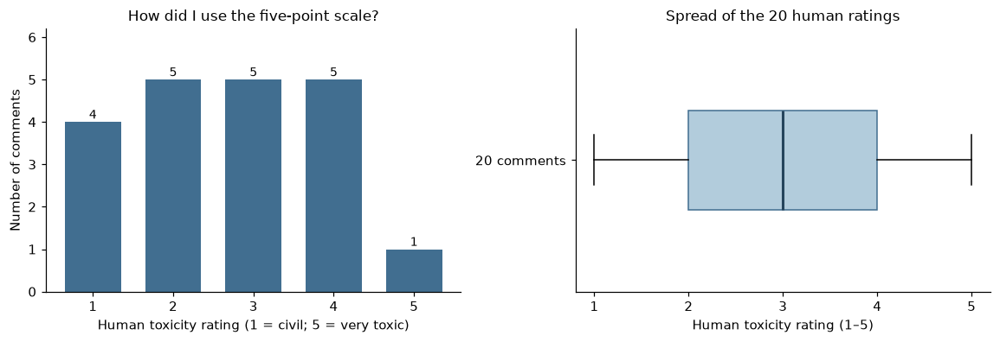

Human: 9 civil, 11 toxic; median 3.


In [3]:
items = pd.read_csv(ROOT / "items/items.csv")[["id", "text"]].copy()
human = pd.read_csv(ROOT / "items/items_rated.csv")[["id", "text", "rating", "label", "evidence"]].copy()

for df in (items, human):
    df["id"] = pd.to_numeric(df.id).astype(int)
    df.sort_values("id", inplace=True)
    df.reset_index(drop=True, inplace=True)
human["rating"] = pd.to_numeric(human.rating, errors="raise").astype(int)
assert len(items) == len(human) == 20 and items.id.is_unique and human.id.is_unique
assert items[["id", "text"]].equals(human[["id", "text"]]), "items.csv and items_rated.csv differ"
assert human.rating.between(1, 5).all()
assert (human.label.str.lower() == np.where(human.rating <= 2, "civil", "toxic")).all()
assert all(all(e.strip() in r.text for e in str(r.evidence).split("||"))
           for r in human.itertuples() if r.rating >= 3)
IDS = items.id.tolist()
REF = human.set_index("id").rating.reindex(IDS)
human.to_csv(TABLE / "human_reference.csv", index=False)
print("Human annotations — all 20 comments")
display(HTML(human.to_html(index=False, escape=True)))

fig, axs = plt.subplots(1, 2, figsize=(10.6, 3.7))
counts = human.rating.value_counts().reindex(range(1,6), fill_value=0)
axs[0].bar(counts.index, counts.values, color="#416e90", width=.7)
for x, y in counts.items(): axs[0].text(x, y+.08, str(y), ha="center", fontsize=9)
axs[0].set(title="How did I use the five-point scale?", xlabel="Human toxicity rating (1 = civil; 5 = very toxic)",
           ylabel="Number of comments", xticks=range(1,6), ylim=(0, max(counts)+1.2))
axs[1].boxplot(human.rating, vert=False, patch_artist=True, widths=.38,
               boxprops={"facecolor":"#b2ccdc","edgecolor":"#416e90"}, medianprops={"color":"#25445c","linewidth":2})
axs[1].set(title="Spread of the 20 human ratings", xlabel="Human toxicity rating (1–5)",
           yticks=[1], yticklabels=["20 comments"], xlim=(.8,5.2), xticks=range(1,6))
fig.tight_layout(); fig.savefig(FIG / "01_human_reference.png", bbox_inches="tight"); plt.show()
print(f"Human: {(human.rating<=2).sum()} civil, {(human.rating>=3).sum()} toxic; median {human.rating.median():g}.")

## Conversation context and model interface

One conversation is reused across every model, persona and prompting condition. The notebook searches for an existing `conversations.jsonl` (including older output locations), validates all 20 original texts, and copies it into the new result directory. Only when no complete source is found does it generate discussions with SynDisco. A discussion has three participants and four replies. The conversations provide context only; the **original comment** is the only annotation target.

Qwen's and Microsoft's official examples use `tokenizer.apply_chat_template(..., add_generation_prompt=True)`. I use the model's own tokenizer template inside a small SynDisco model subclass, so Qwen and Phi receive the appropriate role delimiters. No sampling or hidden retries are used during annotation. The explicit CUDA device check prevents a silent CPU run.

In [4]:
import syndisco
import syndisco.jobs as syndisco_jobs
from transformers import AutoModelForCausalLM
from transformers import logging as hf_logging
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
logging.getLogger("transformers.generation.utils").setLevel(logging.ERROR)

@contextmanager
def quiet_jobs():
    with patch.object(syndisco_jobs, "tqdm", lambda iterable, *args, **kw: iterable):
        yield

class NativeChatModel(syndisco.TransformersModel):
    """use the tokenizer's trained chat format for each model family"""
    def _generate_response(self, system_prompt, user_prompt):
        messages = [{"role":"system", "content":system_prompt},
                    {"role":"user", "content":user_prompt}]
        inputs = self.tokenizer.apply_chat_template(
            messages, tokenize=True, add_generation_prompt=True,
            return_dict=True, return_tensors="pt").to(self.model.device)
        with torch.inference_mode():
            generated = self.model.generate(
                **inputs, max_new_tokens=self.max_out_tokens,
                do_sample=False, repetition_penalty=1.05,
                pad_token_id=self.tokenizer.eos_token_id)
        return self.tokenizer.decode(
            generated[0, inputs["input_ids"].shape[-1]:],
            skip_special_tokens=True).strip()

def make_model(name, max_tokens):
    if not torch.cuda.is_available():
        raise RuntimeError("CUDA not detected; refusing a silent CPU fallback")
    loader = AutoModelForCausalLM.from_pretrained
    def gpu_loader(*args, **kwargs):
        kwargs["device_map"] = "cuda:0"
        return loader(*args, **kwargs)
    with patch.object(AutoModelForCausalLM, "from_pretrained", side_effect=gpu_loader):
        llm = NativeChatModel(model_path=MODEL_PATHS[name], name=name,
                              max_out_tokens=max_tokens)
    devices = {p.device.type for p in llm.model.parameters()}
    if devices != {"cuda"}:
        raise RuntimeError(f"Model not entirely on GPU: {devices}")
    print(f"{name} loaded on {llm.model.device}")
    return llm

def release_model(llm):
    if hasattr(llm, "model"): del llm.model
    if hasattr(llm, "tokenizer"): del llm.tokenizer
    del llm
    gc.collect(); torch.cuda.empty_cache()

def read_jsonl(path):
    return [json.loads(s) for s in path.read_text(encoding="utf-8").splitlines() if s.strip()] if path.exists() else []

def append_jsonl(path, row):
    with path.open("a", encoding="utf-8") as f:
        f.write(json.dumps(row, ensure_ascii=False) + "\n")

In [5]:
DISCUSSION_POOL = [
    {"username":"Lea_24", "age":24, "occupation":"student", "residence":"large city"},
    {"username":"Sam_57", "age":57, "occupation":"shop owner", "residence":"small town"},
    {"username":"Priya_41", "age":41, "occupation":"volunteer", "residence":"suburb"},
    {"username":"Alex_69", "age":69, "occupation":"retired electrician", "residence":"rural town"},
    {"username":"Nora_35", "age":35, "occupation":"journalist", "residence":"large city"},
    {"username":"Mika_30", "age":30, "occupation":"software developer", "residence":"small town"},
]
DISCUSSION_INSTRUCTIONS = (
    "Reply in English with one or two complete sentences to the ongoing news-site discussion. "
    "Respond to the original item and earlier replies, adding a new point or respectful disagreement. "
    "Avoid inventing background details, repetition, self-address and toxicity ratings."
)
CONV_PATH = OUT / "conversations.jsonl"
SOURCES = [ROOT / "conversations.jsonl", ROOT / "output" / "three_models_v1" / "conversations.jsonl",
           ROOT / "output" / "revision_v2" / "conversations.jsonl",
           ROOT / "output" / "conversations.jsonl"]
if not CONV_PATH.exists():
    for path in SOURCES:
        if path.exists():
            candidate = read_jsonl(path)
            d = {int(x["id"]): x for x in candidate}
            if len(d) == 20 and set(d) == set(IDS) and all(
                d[int(r.id)]["original_text"] == r.text for r in items.itertuples(index=False)):
                shutil.copyfile(path, CONV_PATH)
                print("Reusing validated conversations from", path)
                break

CONVERSATIONS = {int(x["id"]): x for x in read_jsonl(CONV_PATH)}
assert set(CONVERSATIONS).issubset(set(IDS))
assert all(CONVERSATIONS[int(r.id)]["original_text"] == r.text
           for r in items.itertuples(index=False) if int(r.id) in CONVERSATIONS)
rng = random.Random(EXPERIMENT_SEED)
pending = []
for item in items.itertuples(index=False):
    picked = rng.sample(DISCUSSION_POOL, 3)
    if int(item.id) not in CONVERSATIONS:
        pending.append((item, picked))

if pending:
    if not RUN_INFERENCE: raise RuntimeError("Missing conversations and inference disabled")
    llm = make_model("Qwen2.5-7B", max_tokens=110)
    try:
        for item, picked in tqdm(pending, desc="Discussions"):
            shared = "Every speaker has read this original news comment:\n" + item.text
            actors = [syndisco.Actor(model=llm, persona=p, context=shared,
                        instructions=DISCUSSION_INSTRUCTIONS, name=p["username"]) for p in picked]
            discussion = syndisco.Discussion(
                next_turn_manager=syndisco.QueueTurnManager(actors), users=actors,
                conv_len=4, seed_opinions=[item.text], seed_opinion_usernames=["OriginalPoster"])
            with quiet_jobs(): discussion.begin(verbose=False)
            messages = [{"name":x["name"], "text":x["text"]} for x in discussion.get_logs()]
            row = {"id":int(item.id), "original_text":item.text,
                   "participants":picked, "messages":messages, "generator_model":MODEL_PATHS["Qwen2.5-7B"]}
            append_jsonl(CONV_PATH, row)
            CONVERSATIONS[int(item.id)] = row
    finally:
        release_model(llm)

assert len(CONVERSATIONS) == 20 and set(CONVERSATIONS) == set(IDS)
conv_rows = []
for k in IDS:
    messages = CONVERSATIONS[k]["messages"]
    assert len(messages) == 5 and messages[0]["text"] == items.set_index("id").loc[k,"text"]
    assert len({m["name"] for m in messages[1:]}) == 3
    for turn, msg in enumerate(messages):
        conv_rows.append({"id":k, "turn":turn, "speaker":msg["name"], "text":msg["text"]})
conv_df = pd.DataFrame(conv_rows)
conv_df.to_csv(TABLE / "conversations_readable.csv", index=False)
display(HTML('<details><summary>Read the original comments and all 20 conversations (100 messages)</summary>'
             '<div style="max-height:460px;overflow:auto">' + conv_df.to_html(index=False,escape=True) + '</div></details>'))
print("Conversations ready:", len(CONVERSATIONS))

Reusing validated conversations from /opt/george-data/Documents/uni/practical-ds/assignment-1/output/three_models_v1/conversations.jsonl


id,turn,speaker,text
1,0,OriginalPoster,Its Sussex Dr. you idiot and Harper lived prior to the election.
1,1,Lea_24,"I understand the address is Sussex Dr., but could you clarify why that's relevant to Harper's actions during the election?"
1,2,Sam_57,"While the address is indeed Sussex Dr., it might be more relevant to discuss where Harper was living at the time of key events during the campaign rather than just their permanent residence. Could you provide more context on how this information impacts the situation?"
1,3,Nora_35,"Lea_24 raises a good point; while the address is important, it would be helpful to know if Sussex Dr. was Harper's primary residence during the campaign or if they had a different place they were actively using. This distinction could affect how we interpret their activities and interactions during the election period."
1,4,Lea_24,"Lea_24 raises a valid point about the relevance of the address. However, I think it’s also important to consider whether there were any significant changes in Harper’s living arrangements around the time of the election. If they moved during the campaign, that could have implications for their accessibility and interactions with voters. Can anyone provide more details on that aspect?"
2,0,OriginalPoster,The republicans have the White House and the majority of the senate and House. That being said even a snail has made more progress than the idiot in chief and his circus of clowns. The Chump train is heading for certain derailment and the Chumpsters are stuck on it because they have s**t for brains.
2,1,Sam_57,"I understand your frustration, but it's important to consider both sides of an issue. While the current administration might face challenges, many policies and appointments still require bipartisan support. How do you think the opposition can work towards constructive solutions despite these dynamics?"
2,2,Mika_30,"While I agree that the current administration faces significant challenges, it's also crucial to recognize the importance of bipartisanship in moving forward. How do you think the opposition can leverage their position to push for meaningful reforms without just criticizing from the sidelines?"
2,3,Nora_35,"As a journalist, I appreciate the nuanced perspective brought up by Sam_57 and Mika_30. It's true that while the current administration faces challenges, there are opportunities for constructive dialogue and collaboration across party lines. However, I believe it's equally important to hold those in power accountable. How can we ensure that the opposition uses their platform not just to criticize, but to propose viable alternatives and work towards tangible solutions?"
2,4,Sam_57,"I appreciate the nuanced perspectives shared here. While it’s important to hold those in power accountable, I also believe in the value of constructive criticism. How can we encourage leaders from all sides to focus on practical solutions and less on partisan bickering, especially when it comes to critical issues like infrastructure and healthcare?"


Conversations ready: 20


## Personas and the common rating protocol

This is a factorial design rather than a collection of unrelated character sketches: changing one attribute at a time lets me compare the effects of age, gender and political outlook. The baseline has no attributes. The same identities appear in every model and panel in the same order.

The five-shot examples are deliberately **outside** the 20-item evaluation sample. They demonstrate all five rating levels, but do not provide labels for the test items. The rating definitions are identical in zero-shot and five-shot; only the five examples are added. For the assignment's paired context comparison, instructions are unchanged within each shot condition.

In [6]:
PERSONAS = {"baseline":{}}
for political, age, gender in product(
        ("progressive", "centrist", "conservative"), ("18–29", "55–70"), ("woman", "man")):
    name = f"{political} | {age} | {gender}"
    PERSONAS[name] = {"political_outlook":political,"age_range":age,"gender":gender}
NAMES = list(PERSONAS)
CODE = {name:("B" if name=="baseline" else f"P{i:02}") for i,name in enumerate(NAMES)}
persona_df = pd.DataFrame([{"code":CODE[n],"annotator":n,**p} for n,p in PERSONAS.items()]).fillna("—")
assert len(PERSONAS) == 13
persona_df.to_csv(TABLE / "persona_grid.csv", index=False)
display(persona_df)

BASE_RUBRIC = (
    "Rate the toxicity of the ORIGINAL COMMENT, not the discussion about it. "
    "Judge the language rather than political agreement. "
    "1 = civil or respectful disagreement; "
    "2 = mildly rude or dismissive without direct abuse; "
    "3 = clear insult or hostile personal remark; "
    "4 = strongly degrading or repeated abuse; "
    "5 = explicit threat, wish of serious harm, or extreme targeted abuse. "
    "Choose the rating before selecting evidence. "
    "Return a single line: NUMBER | EVIDENCE. NUMBER is an integer 1 to 5. "
    "For 1 or 2, use not needed as evidence. For 3 to 5, copy one short continuous passage verbatim "
    "from the ORIGINAL COMMENT. No explanation, introductory text, paraphrase or extra lines."
)
FEW_SHOTS = """
Examples (different from the comments you will rate):
Comment: I disagree with the proposal, but appreciate the explanation.
Answer: 1 | not needed
Comment: That is a pretty silly suggestion.
Answer: 2 | not needed
Comment: You are an idiot.
Answer: 3 | idiot
Comment: You're a worthless fraud and an embarrassment.
Answer: 4 | worthless fraud
Comment: I will hurt you if you say that again.
Answer: 5 | I will hurt you
""".strip()
INSTRUCTIONS = {"zero-shot":BASE_RUBRIC,
                "five-shot":BASE_RUBRIC + "\n\n" + FEW_SHOTS + "\n\nNow rate the new original comment."}
PROTOCOL_HASH = hashlib.sha256(json.dumps(
    {"model_paths":MODEL_PATHS, "instructions":INSTRUCTIONS,
     "context_levels":CONTEXTS, "personas":PERSONAS}, sort_keys=True).encode()).hexdigest()
print("Protocol checksum:", PROTOCOL_HASH[:16])

,code,annotator,political_outlook,age_range,gender
0,B,baseline,—,—,—
1,P01,progressive | 18–29 | woman,progressive,18–29,woman
2,P02,progressive | 18–29 | man,progressive,18–29,man
3,P03,progressive | 55–70 | woman,progressive,55–70,woman
4,P04,progressive | 55–70 | man,progressive,55–70,man
5,P05,centrist | 18–29 | woman,centrist,18–29,woman
6,P06,centrist | 18–29 | man,centrist,18–29,man
7,P07,centrist | 55–70 | woman,centrist,55–70,woman
8,P08,centrist | 55–70 | man,centrist,55–70,man
9,P09,conservative | 18–29 | woman,conservative,18–29,woman


Protocol checksum: 61e712c5df14da14


## Separating ratings from formatting failures

Earlier runs showed that rejecting a civil rating because it contained unnecessary evidence made the surviving ratings appear 100% toxic. Here a clearly recoverable numeric label is **kept** even when the response violates the evidence rule. Format or quotation errors are flagged in separate columns and counted. Only ambiguous or missing 1–5 ratings become missing values.

This makes the primary agreement analysis about **rating decisions**, while strict annotation compliance remains a second outcome. It does not excuse incorrect evidence: the original text and raw response remain available for inspection.

In [7]:
def parse_answer(raw, original):
    text = str(raw or "").strip()
    rating, evidence, format_status = None, "", "nonstandard"
    # prefer a number at the beginning, then a clearly labeled rating
    m = re.search(r"(?m)^\s*(?:rating|score|answer)?\s*[:=]?\s*([1-5])\s*[|:—-]\s*(.*)$", text, re.I)
    if m is None:
        m = re.search(r"(?i)\b(?:rating|score|answer)\s*[:=]\s*([1-5])\b", text)
    if m is None:
        m = re.search(r'(?:"rating"|"score"|"answer")\s*:\s*([1-5])\b', text, re.I)
    if m is None:
        m = re.search(r"(?m)^\s*([1-5])\s*$", text)
    if m is None:
        # allow a clearly delimited rating after a copied template
        m = re.search(r"(?<!\d)([1-5])\s*\|\s*([^\r\n]+)", text)
    if m is not None:
        rating = int(m.group(1))
        evidence = m.group(2).strip() if m.lastindex and m.lastindex >= 2 else ""
        format_status = "standard" if re.fullmatch(r"[1-5]\s*\|\s*[^\r\n]+",text) else "nonstandard"
    if rating is None:
        return {"rating":None,"label":None,"evidence":text,"rating_status":"unparseable",
                "evidence_status":"not assessed","format_status":"nonstandard","strict_valid":False}
    evidence = evidence.strip().strip('"“”').strip()
    label = "civil" if rating <= 2 else "toxic"
    if rating <= 2:
        ev_status = "compliant" if evidence.lower().rstrip(".") == "not needed" else "unexpected civil evidence"
    elif not evidence:
        ev_status = "missing toxic evidence"
    elif evidence in original:
        ev_status = "compliant"
    elif evidence.casefold() in original.casefold():
        ev_status = "capitalization differs"
    else:
        ev_status = "nonverbatim evidence"
    return {"rating":rating,"label":label,"evidence":evidence,
            "rating_status":"usable","evidence_status":ev_status,"format_status":format_status,
            "strict_valid": bool(format_status == "standard" and ev_status == "compliant")}

assert parse_answer("2 | RINO", "A comment")['rating'] == 2
assert parse_answer("2 | RINO", "A comment")['evidence_status'] == 'unexpected civil evidence'
assert parse_answer("3 | idiot", "you idiot")['strict_valid']
assert parse_answer("rating | evidence. 5 | you idiot", "you idiot")['rating'] == 5
assert parse_answer("not sure", "you idiot")['rating'] is None
print("Parser tests passed: numeric judgments and evidence compliance are independent.")

Parser tests passed: numeric judgments and evidence compliance are independent.


## A small pilot before the complete run

Three held-out **evaluation items** with differing human severity scores are used as a *format diagnostic*, not as examples in the prompts. Two annotators (baseline and one persona) run in all four conditions for each model. The pilot records issues without changing ratings, prompts or parsers after observing model labels. The same attempts count toward the full study and are not regenerated.

The full factorial requires **3 models × 13 annotators × 20 items × 2 contexts × 2 prompt modes = 3,120 attempts**. Each response is checkpointed in the new output directory. The original human ratings and imported conversations are never changed.

In [8]:
ANNOT_PATH = OUT / "annotations.jsonl"
BASE_CONTEXT = "You are annotating an original comment from a news-site discussion."

def context_for(item_id, condition):
    if condition == "no context": return BASE_CONTEXT
    messages = CONVERSATIONS[int(item_id)]["messages"][1:]
    return BASE_CONTEXT + "\nDiscussion about the original comment (context only):\n" + "\n".join(
        f"{m['name']}: {m['text']}" for m in messages)

def annotate_one(llm, model_name, item, annotator, condition, shot):
    context = context_for(item.id, condition)
    row = {"model":model_name, "annotator":annotator, "id":int(item.id), "text":item.text,
           "condition":condition, "prompting":shot, "raw_answer":"", "prompt":"",
           "system_prompt":"", "user_prompt":"", "error":"", "protocol_hash":PROTOCOL_HASH}
    try:
        actor = syndisco.Actor(model=llm, persona=PERSONAS[annotator], context=context,
                               instructions=INSTRUCTIONS[shot], name=annotator, is_annotator=True)
        one = syndisco.Logs(); one.append("OriginalComment", item.text)
        row["system_prompt"] = actor.get_system_prompt()
        job = syndisco.Annotation(annotator=actor, discussion_logs=one)
        with quiet_jobs(): job.begin(verbose=False)
        logs = list(job.get_logs())
        assert len(logs) == 1
        row["raw_answer"] = str(logs[0].get("text", ""))
        row["user_prompt"] = str(logs[0].get("prompt", ""))
        row.update(parse_answer(row["raw_answer"], item.text))
    except Exception as exc:
        row["error"] = f"{type(exc).__name__}: {exc}"
        row.update(parse_answer("", item.text))
    row["prompt"] = json.dumps({"persona":PERSONAS[annotator], "instructions":INSTRUCTIONS[shot],
                                "context":context, "system_prompt":row["system_prompt"],
                                "user_prompt":row["user_prompt"]}, ensure_ascii=False)
    return row

def run_annotation_jobs(pilot_only=False):
    saved = read_jsonl(ANNOT_PATH)
    keys = [(r["model"], r["annotator"], r["condition"],r["prompting"],int(r["id"])) for r in saved]
    assert len(set(keys)) == len(keys), "duplicate completed annotations"
    assert all(r["protocol_hash"] == PROTOCOL_HASH for r in saved), "checkpoint uses another protocol"
    
    done = set(keys)
    pilot_items = [items[items.id.eq(k)].iloc[0] for k in (3, 7, 19)]
    all_items = pilot_items if pilot_only else list(items.itertuples(index=False))
    names = ["baseline", NAMES[1]] if pilot_only else NAMES
    for model_name in MODELS:
        jobs = [(ann, cond, shot, item) for shot in PROMPTS for cond in CONTEXTS for ann in names
                for item in all_items if (model_name, ann, cond, shot, int(item.id)) not in done]
        print(f"{model_name}: {len(jobs)} remaining {'pilot' if pilot_only else 'full'} attempts")
        if not jobs: continue
        if not RUN_INFERENCE: raise RuntimeError("Incomplete annotations and RUN_INFERENCE=False")
        llm = make_model(model_name, max_tokens=80)
        try:
            for ann, cond, shot, item in tqdm(jobs, desc=model_name, unit="rating"):
                row = annotate_one(llm, model_name, item, ann, cond, shot)
                append_jsonl(ANNOT_PATH, row)
                done.add((model_name, ann, cond, shot, int(item.id)))
        finally:
            release_model(llm)

run_annotation_jobs(pilot_only=True)
pilot_df = pd.DataFrame(read_jsonl(ANNOT_PATH))
pilot = pilot_df[pilot_df.id.isin((3,7,19)) & pilot_df.annotator.isin(("baseline", NAMES[1]))]
print("Pilot: usability and strict compliance are separate")
display(pilot.groupby(["model","prompting","condition"]).agg(
    attempts=("id","size"), usable=("rating_status",lambda s:(s=="usable").sum()),
    strict=("strict_valid","sum")).reset_index())
display(HTML('<details><summary>Inspect all pilot raw responses and issues</summary><div style="max-height:360px;overflow:auto">' +
             pilot[["model","annotator","id","condition","prompting","raw_answer","rating","evidence_status"]].to_html(index=False,escape=True)+"</div></details>"))

Qwen2.5-7B: 24 remaining pilot attempts
Qwen2.5-7B loaded on cuda:0


Qwen2.5-7B:   0%|          | 0/24 [00:00<?, ?rating/s]

Qwen2.5-3B: 24 remaining pilot attempts
Qwen2.5-3B loaded on cuda:0


Qwen2.5-3B:   0%|          | 0/24 [00:00<?, ?rating/s]

Phi-4-mini: 24 remaining pilot attempts
Phi-4-mini loaded on cuda:0


Phi-4-mini:   0%|          | 0/24 [00:00<?, ?rating/s]

Pilot: usability and strict compliance are separate


,model,prompting,condition,attempts,usable,strict
0,Phi-4-mini,five-shot,discussion context,6,6,6
1,Phi-4-mini,five-shot,no context,6,6,6
2,Phi-4-mini,zero-shot,discussion context,6,6,4
3,Phi-4-mini,zero-shot,no context,6,6,6
4,Qwen2.5-3B,five-shot,discussion context,6,6,1
5,Qwen2.5-3B,five-shot,no context,6,6,2
6,Qwen2.5-3B,zero-shot,discussion context,6,6,4
7,Qwen2.5-3B,zero-shot,no context,6,6,6
8,Qwen2.5-7B,five-shot,discussion context,6,6,3
9,Qwen2.5-7B,five-shot,no context,6,6,3


model,annotator,id,condition,prompting,raw_answer,rating,evidence_status
Qwen2.5-7B,baseline,3,no context,zero-shot,"2 | I still don't believe Candace's story, or HughRG's. They're just making stuff up.",2,unexpected civil evidence
Qwen2.5-7B,baseline,7,no context,zero-shot,1 | not needed,1,compliant
Qwen2.5-7B,baseline,19,no context,zero-shot,"5 | ""Support mental health or I'll kill you and your family.""",5,compliant
Qwen2.5-7B,progressive | 18–29 | woman,3,no context,zero-shot,"2 | I still don't believe Candace's story, or HughRG's. They're just making stuff up.",2,unexpected civil evidence
Qwen2.5-7B,progressive | 18–29 | woman,7,no context,zero-shot,"2 | All you lazy, entitled people should spend a day in the shoes of a kid living in a garbage dump on one of the island countries.",2,unexpected civil evidence
Qwen2.5-7B,progressive | 18–29 | woman,19,no context,zero-shot,"5 | ""Support mental health or I'll kill you and your family.""",5,compliant
Qwen2.5-7B,baseline,3,discussion context,zero-shot,"2 | I still don't believe Candace's story, or HughRG's. They're just making stuff up.",2,unexpected civil evidence
Qwen2.5-7B,baseline,7,discussion context,zero-shot,1 | Not needed.,1,compliant
Qwen2.5-7B,baseline,19,discussion context,zero-shot,"4 | ""Support mental health or I'll kill you and your family.""",4,compliant
Qwen2.5-7B,progressive | 18–29 | woman,3,discussion context,zero-shot,"2 | I still don't believe Candace's story, or HughRG's. They're just making stuff up.",2,unexpected civil evidence


In [9]:
display(
    pd.crosstab(
        [pilot["model"], pilot["prompting"]],
        pilot["rating"],
        dropna=False,
    )
)

rating                1  2  3  4   5
model      prompting                
Phi-4-mini five-shot  0  0  0  8   4
           zero-shot  0  0  1  5   6
Qwen2.5-3B five-shot  0  0  6  0   6
           zero-shot  0  0  2  0  10
Qwen2.5-7B five-shot  2  6  0  0   4
           zero-shot  2  6  0  2   2

In [10]:
run_annotation_jobs(pilot_only=False)
A = pd.DataFrame(read_jsonl(ANNOT_PATH))
A["id"] = pd.to_numeric(A.id).astype(int)
A["rating"] = pd.to_numeric(A.rating, errors="coerce")
assert len(A) == 3*13*20*2*2 == 3120
assert not A.duplicated(["model","annotator","condition","prompting","id"]).any()
assert A.groupby(["model","annotator","condition","prompting"]).size().eq(20).all()
assert A.loc[A.rating.notna(),"rating"].between(1,5).all()
assert all(r.text == items.set_index('id').loc[r.id,'text'] for r in A.itertuples())
A.to_csv(OUT / "annotations.csv", index=False)
A[A.rating_status.ne("usable") | ~A.strict_valid].to_csv(TABLE / "format_and_evidence_issues.csv", index=False)
print(f"Attempts: {len(A)}; usable ratings: {A.rating.notna().sum()}; strictly compliant: {A.strict_valid.sum()}")
print("All 3,120 records are available in output and at the end of the notebook.")

Qwen2.5-7B: 1016 remaining full attempts
Qwen2.5-7B loaded on cuda:0


Qwen2.5-7B:   0%|          | 0/1016 [00:00<?, ?rating/s]

Qwen2.5-3B: 1016 remaining full attempts
Qwen2.5-3B loaded on cuda:0


Qwen2.5-3B:   0%|          | 0/1016 [00:00<?, ?rating/s]

Phi-4-mini: 1016 remaining full attempts
Phi-4-mini loaded on cuda:0


Phi-4-mini:   0%|          | 0/1016 [00:00<?, ?rating/s]

Attempts: 3120; usable ratings: 3080; strictly compliant: 2180
All 3,120 records are available in output and at the end of the notebook.


## Can the models provide usable ratings?

The first result is **rating availability**, not agreement. A recoverable 1–5 score remains in the analysis even if the evidence field contains an extra phrase or incorrect quotation. Strict compliance is still shown separately. This prevents formatting errors from creating an artificial class imbalance while making it possible to compare how prompting affects the quality of complete annotations.

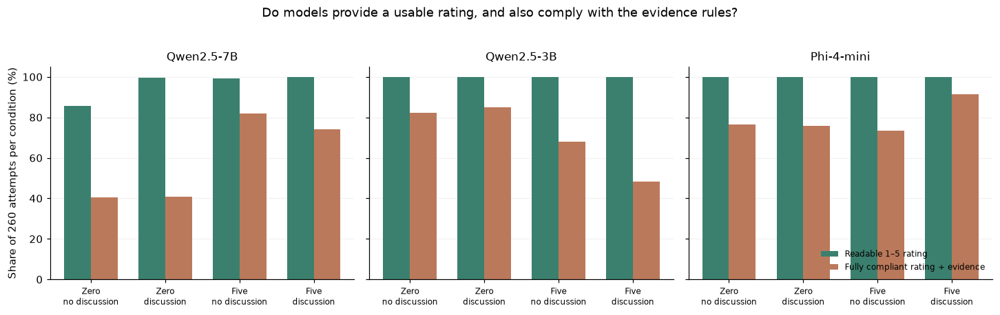

,model,prompting,condition,attempts,usable,strict,rating_pct,strict_pct
0,Qwen2.5-7B,zero-shot,no context,260,223,105,85.769231,40.384615
1,Qwen2.5-7B,zero-shot,discussion context,260,259,106,99.615385,40.769231
2,Qwen2.5-7B,five-shot,no context,260,258,213,99.230769,81.923077
3,Qwen2.5-7B,five-shot,discussion context,260,260,193,100.000000,74.230769
4,Qwen2.5-3B,zero-shot,no context,260,260,214,100.000000,82.307692
5,Qwen2.5-3B,zero-shot,discussion context,260,260,221,100.000000,85.000000
6,Qwen2.5-3B,five-shot,no context,260,260,177,100.000000,68.076923
7,Qwen2.5-3B,five-shot,discussion context,260,260,126,100.000000,48.461538
8,Phi-4-mini,zero-shot,no context,260,260,199,100.000000,76.538462
9,Phi-4-mini,zero-shot,discussion context,260,260,197,100.000000,75.769231


In [11]:
validity = A.groupby(["model","prompting","condition"], sort=False).agg(
    attempts=("id","size"), usable=("rating",lambda s:s.notna().sum()),
    strict=("strict_valid","sum")).reset_index()
validity["rating_pct"] = 100*validity.usable/validity.attempts
validity["strict_pct"] = 100*validity.strict/validity.attempts
validity.to_csv(TABLE/"validity_by_condition.csv",index=False)

fig,axs = plt.subplots(1,3,figsize=(13.3,4.0),sharey=True)
for ax,model in zip(axs, MODELS):
    part=validity[validity.model.eq(model)].set_index(["prompting","condition"])
    order=list(product(PROMPTS,CONTEXTS)); x=np.arange(4)
    ax.bar(x-.18,[part.loc[o,"rating_pct"] for o in order],.36,color="#3b806e",label="Readable 1–5 rating")
    ax.bar(x+.18,[part.loc[o,"strict_pct"] for o in order],.36,color="#bb795b",label="Fully compliant rating + evidence")
    ax.set(title=model,ylim=(0,105),xticks=x,xticklabels=["Zero\nno discussion","Zero\ndiscussion","Five\nno discussion","Five\ndiscussion"])
    ax.tick_params(axis="x",labelsize=8)
    ax.grid(axis="y",alpha=.16);ax.set_axisbelow(True)
axs[0].set_ylabel("Share of 260 attempts per condition (%)")
axs[-1].legend(frameon=False,fontsize=8,loc="lower right")
fig.suptitle("Do models provide a usable rating, and also comply with the evidence rules?",y=1.03)
fig.tight_layout();fig.savefig(FIG/"02_format_reliability.png",bbox_inches="tight");plt.show()
display(validity)

## Do models use the toxicity scale like the human annotator?

The reference has both civil and toxic comments. A model can obtain seemingly strong inter-persona agreement by predicting one class repeatedly, so label frequencies must be examined before agreement. The chart includes **missing numeric ratings** as a sixth outcome to avoid hiding them from the denominator. Each panel therefore represents all 260 annotation attempts for that model, prompting condition and context.

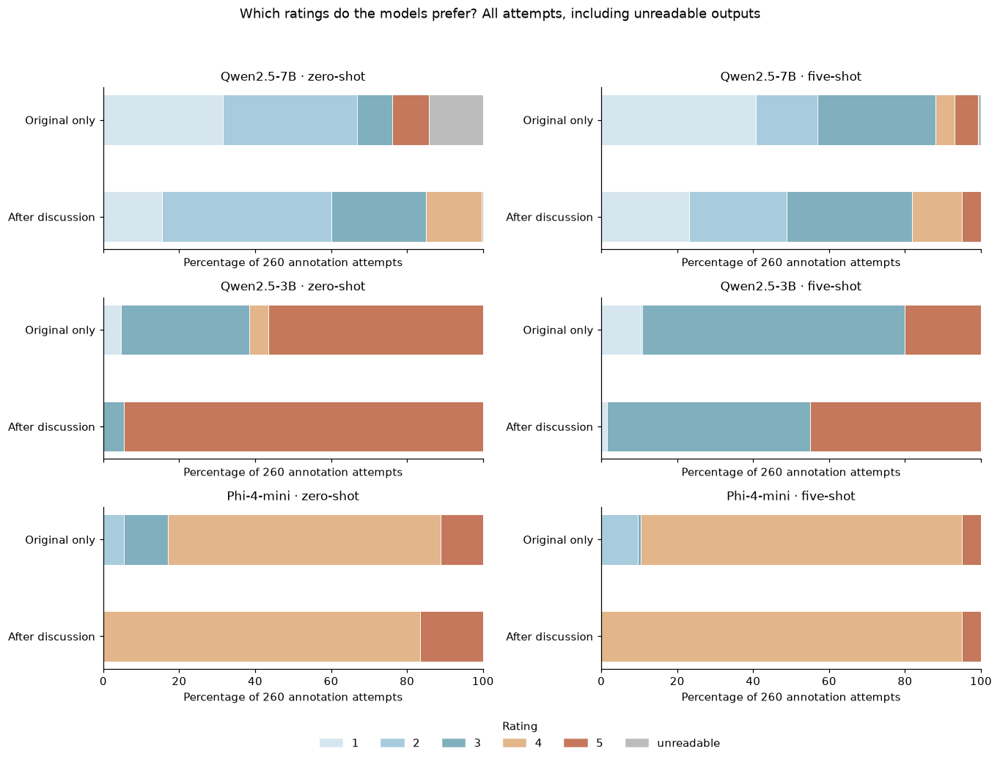

Human counts: {1: 4, 2: 5, 3: 5, 4: 5, 5: 1}


In [12]:
levels=["1","2","3","4","5","unreadable"]
colors=["#d6e6ef","#a8ccdd","#80afbd","#e2b58a","#c5785c","#bcbcbc"]
fig,axs=plt.subplots(3,2,figsize=(12.5,9.1),sharex=True)
dist_rows=[]
for i,model in enumerate(MODELS):
    for j,shot in enumerate(PROMPTS):
        ax=axs[i,j]
        for k,cond in enumerate(CONTEXTS):
            sub=A[(A.model==model)&(A.prompting==shot)&(A.condition==cond)]
            values=sub.rating.map(lambda v: str(int(v)) if pd.notna(v) else "unreadable")
            fr=values.value_counts().reindex(levels,fill_value=0)/len(sub)*100
            bottom=0
            for lev,color in zip(levels,colors):
                v=float(fr[lev]); ax.barh(k,v,left=bottom,height=.52,color=color,
                                          edgecolor="white",linewidth=.6)
                dist_rows.append({"model":model,"prompting":shot,"condition":cond,"rating":lev,"count":int((values==lev).sum())})
                bottom+=v
        ax.set(yticks=[0,1],yticklabels=["Original only","After discussion"],xlim=(0,100),
               title=f"{model} · {shot}",xlabel="Percentage of 260 annotation attempts")
        ax.invert_yaxis()
fig.legend([plt.Rectangle((0,0),1,1,color=c) for c in colors],levels,
           title="Rating",loc="lower center",ncol=6,frameon=False,bbox_to_anchor=(.52,-.01))
fig.suptitle("Which ratings do the models prefer? All attempts, including unreadable outputs",y=1.015)
fig.tight_layout(rect=(0,.05,1,.98));fig.savefig(FIG/"03_severity_distributions.png",bbox_inches="tight");plt.show()
dist_df=pd.DataFrame(dist_rows)
dist_df.to_csv(TABLE/"rating_distribution.csv",index=False)
print("Human counts:",human.rating.value_counts().reindex(range(1,6),fill_value=0).to_dict())

## Agreement with my ratings

Agreement is calculated on matched **item IDs**, rather than array positions. The main measure counts matches out of the original 20 items for each persona, so an unreadable prediction contributes no match. An additional valid-only score divides by the number of readable predictions; this separates genuine rating differences from missing model outputs. Both denominators are exported.

The first chart summarizes the **mean across 12 personas**, with the baseline shown separately in the results table. Exact-rating agreement is necessarily at most binary agreement.

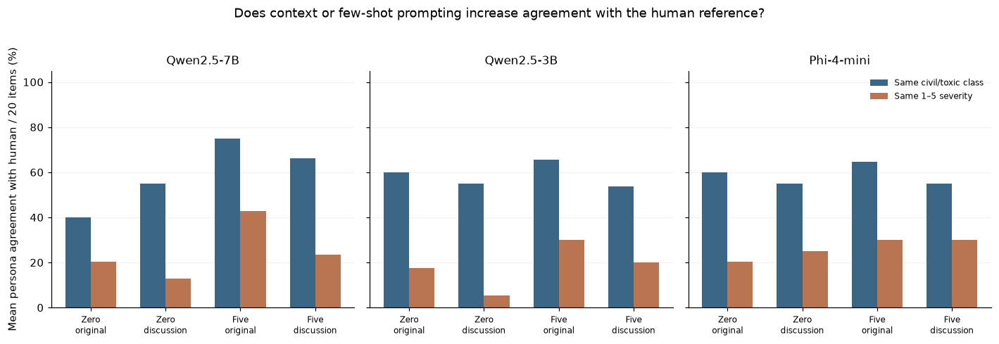

,model,prompting,condition,binary_agreement,exact_agreement,mean_usable
0,Qwen2.5-7B,zero-shot,no context,0.400000,0.204167,17.166667
1,Qwen2.5-7B,zero-shot,discussion context,0.550000,0.129167,20.000000
2,Qwen2.5-7B,five-shot,no context,0.750000,0.429167,19.833333
3,Qwen2.5-7B,five-shot,discussion context,0.662500,0.233333,20.000000
4,Qwen2.5-3B,zero-shot,no context,0.600000,0.175000,20.000000
5,Qwen2.5-3B,zero-shot,discussion context,0.550000,0.054167,20.000000
6,Qwen2.5-3B,five-shot,no context,0.654167,0.300000,20.000000
7,Qwen2.5-3B,five-shot,discussion context,0.537500,0.200000,20.000000
8,Phi-4-mini,zero-shot,no context,0.600000,0.204167,20.000000
9,Phi-4-mini,zero-shot,discussion context,0.550000,0.250000,20.000000


In [13]:
W=A.pivot(index="id",columns=["model","prompting","condition","annotator"],values="rating").reindex(IDS)
def binary(s):
    return s.map(lambda x: "civil" if pd.notna(x) and x<=2 else "toxic" if pd.notna(x) else np.nan)
def agreement(a,b):
    left,right=a.reindex(IDS),b.reindex(IDS)
    valid=left.notna() & right.notna()
    matches=int((valid & left.eq(right)).sum()); n=int(valid.sum())
    return matches,n,matches/20, matches/n if n else np.nan
def both_agreements(a,b):
    cm,n,ca,cv=agreement(binary(a),binary(b))
    em,_,ea,ev=agreement(a,b)
    return {"usable_pairs":n,"binary_matches":cm,"exact_matches":em,
            "binary_all":ca,"exact_all":ea,"binary_valid":cv,"exact_valid":ev}
rows=[]
for model in MODELS:
  for shot in PROMPTS:
    for cond in CONTEXTS:
      for name in NAMES:
        rows.append({"model":model,"prompting":shot,"condition":cond,
                     "annotator":name,"code":CODE[name],
                     **both_agreements(REF,W[(model,shot,cond,name)])})
H=pd.DataFrame(rows);H.to_csv(TABLE/"agreement_with_human.csv",index=False)
summary=H[H.annotator.ne("baseline")].groupby(["model","prompting","condition"],sort=False).agg(
    binary_agreement=("binary_all","mean"),exact_agreement=("exact_all","mean"),
    mean_usable=("usable_pairs","mean")).reset_index()
fig,axs=plt.subplots(1,3,figsize=(13,4.25),sharey=True)
for ax,model in zip(axs,MODELS):
    part=summary[summary.model==model].set_index(["prompting","condition"])
    order=list(product(PROMPTS,CONTEXTS)); xx=np.arange(4)
    for off,key,color,label in [(-.17,"binary_agreement","#3b6686","Same civil/toxic class"),
                                (.17,"exact_agreement","#b97552","Same 1–5 severity")]:
        vals=[part.loc[o,key]*100 for o in order]
        ax.bar(xx+off,vals,.34,color=color,label=label)
    ax.set(title=model,ylim=(0,105),xticks=xx,
           xticklabels=["Zero\noriginal","Zero\ndiscussion","Five\noriginal","Five\ndiscussion"])
    ax.tick_params(axis="x",labelsize=8);ax.grid(axis="y",alpha=.16);ax.set_axisbelow(True)
axs[0].set_ylabel("Mean persona agreement with human / 20 items (%)")
axs[-1].legend(frameon=False,fontsize=8,loc="upper right")
fig.suptitle("Does context or few-shot prompting increase agreement with the human reference?",y=1.035)
fig.tight_layout();fig.savefig(FIG/"04_human_agreement.png",bbox_inches="tight");plt.show()
display(summary)

## Which persona is closest to the human reference?

The closest persona is ranked by binary agreement, using exact agreement to break ties.The lookup table retains the complete identity attributes; plots always use the same `B`, `P01`–`P12` order.

,model,prompting,condition,closest_persona,binary_matches_of_20,exact_matches_of_20,baseline_binary_matches_of_20,baseline_exact_matches_of_20
0,Qwen2.5-7B,zero-shot,no context,centrist | 18–29 | woman,9,5,10,6
1,Qwen2.5-7B,zero-shot,discussion context,progressive | 55–70 | woman,12,3,11,5
2,Qwen2.5-7B,five-shot,no context,centrist | 18–29 | woman,17,10,15,8
3,Qwen2.5-7B,five-shot,discussion context,progressive | 18–29 | man,14,5,13,5
4,Qwen2.5-3B,zero-shot,no context,progressive | 55–70 | woman,13,2,11,2
5,Qwen2.5-3B,zero-shot,discussion context,conservative | 18–29 | man,11,2,11,1
6,Qwen2.5-3B,five-shot,no context,conservative | 55–70 | woman,14,7,14,7
7,Qwen2.5-3B,five-shot,discussion context,progressive | 18–29 | woman,11,4,10,3
8,Phi-4-mini,zero-shot,no context,centrist | 18–29 | woman,12,5,13,5
9,Phi-4-mini,zero-shot,discussion context,progressive | 18–29 | woman,11,5,11,5


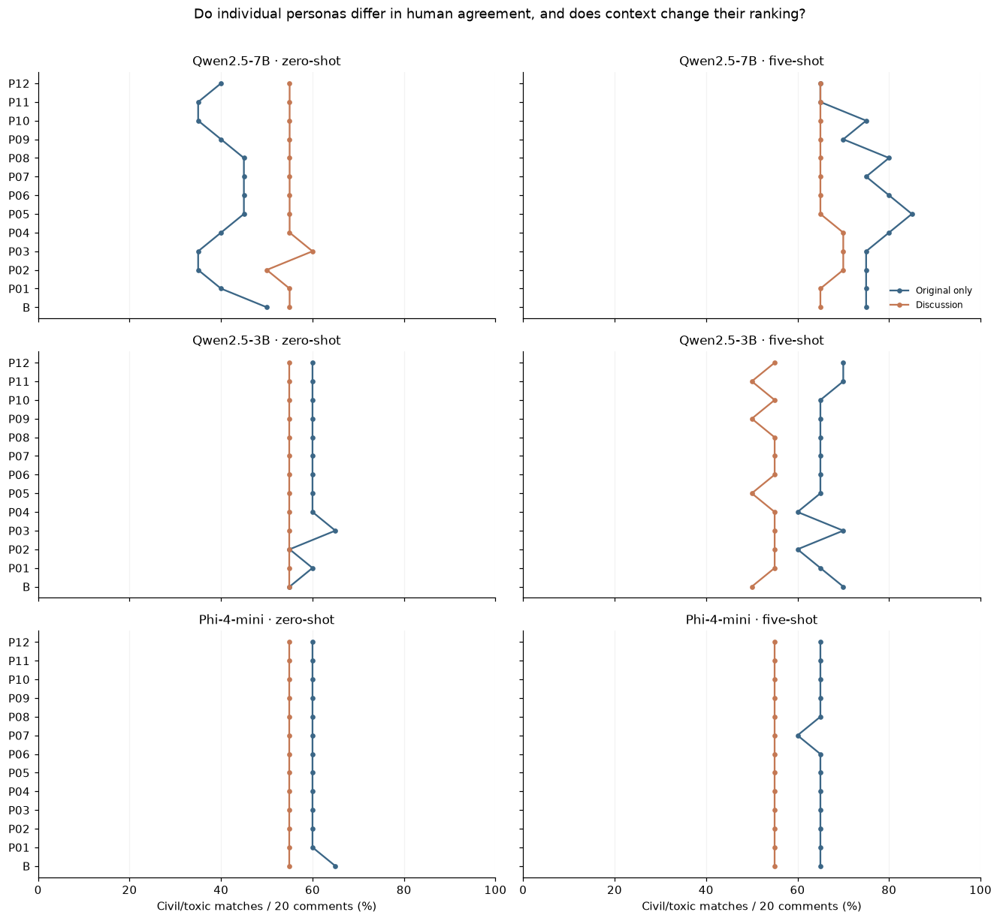

,code,annotator
0,B,baseline
1,P01,progressive | 18–29 | woman
2,P02,progressive | 18–29 | man
3,P03,progressive | 55–70 | woman
4,P04,progressive | 55–70 | man
5,P05,centrist | 18–29 | woman
6,P06,centrist | 18–29 | man
7,P07,centrist | 55–70 | woman
8,P08,centrist | 55–70 | man
9,P09,conservative | 18–29 | woman


In [14]:
closest=[]
for model,shot,cond in product(MODELS,PROMPTS,CONTEXTS):
    sub=H[(H.model==model)&(H.prompting==shot)&(H.condition==cond)]
    top=sub[sub.annotator.ne("baseline")].sort_values(
        ["binary_all","exact_all"],ascending=False).iloc[0]
    base=sub[sub.annotator.eq("baseline")].iloc[0]
    closest.append({"model":model,"prompting":shot,"condition":cond,
                    "closest_persona":top.annotator,"binary_matches_of_20":int(top.binary_matches),
                    "exact_matches_of_20":int(top.exact_matches),"baseline_binary_matches_of_20":int(base.binary_matches),
                    "baseline_exact_matches_of_20":int(base.exact_matches)})
closest=pd.DataFrame(closest);closest.to_csv(TABLE/"closest_personas.csv",index=False)
display(closest)
fig,axs=plt.subplots(3,2,figsize=(12.2,11),sharex=True,sharey=True)
for i,model in enumerate(MODELS):
  for j,shot in enumerate(PROMPTS):
    ax=axs[i,j]
    part=H[(H.model==model)&(H.prompting==shot)].set_index(["condition","annotator"])
    for k,cond in enumerate(CONTEXTS):
        vals=part.loc[cond].reindex(NAMES).binary_all.to_numpy()*100
        ax.plot(vals,np.arange(13),"o-",markersize=3.4,
                color="#3b6686" if k==0 else "#c47853",label="Original only" if k==0 else "Discussion")
    ax.set(title=f"{model} · {shot}",xlim=(0,100),yticks=np.arange(13),
           yticklabels=[CODE[n] for n in NAMES]); ax.grid(axis="x",alpha=.15)
    if i==2:ax.set_xlabel("Civil/toxic matches / 20 comments (%)")
axs[0,1].legend(frameon=False,fontsize=8,loc="lower right")
fig.suptitle("Do individual personas differ in human agreement, and does context change their ranking?",y=1.01)
fig.tight_layout();fig.savefig(FIG/"05_persona_human_agreement.png",bbox_inches="tight");plt.show()
display(persona_df[["code","annotator"]])

## What changes when the discussion is introduced?

This is the **paired** comparison required by the assignment. I compare each persona's rating on the same item, with the same model and few-shot setting. A change is reported only when both numeric ratings are available. The figure distinguishes higher toxicity, lower toxicity and unchanged ratings; the unavailable pairs are shown rather than treated as no change.

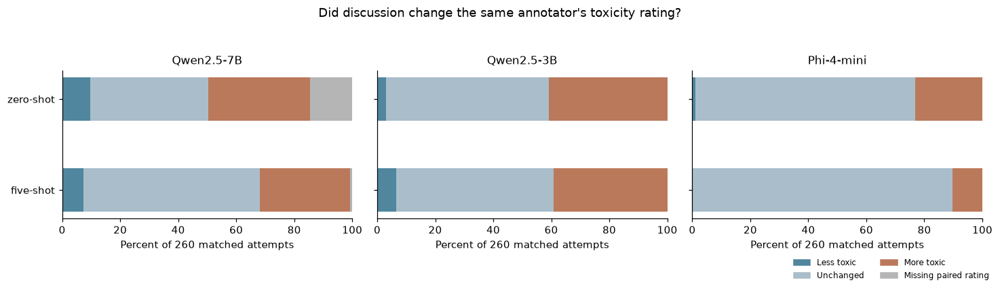

transition,model,prompting,lower,same,higher,unmatched
0,Phi-4-mini,five-shot,0,233,27,0
1,Phi-4-mini,zero-shot,3,197,60,0
2,Qwen2.5-3B,five-shot,17,141,102,0
3,Qwen2.5-3B,zero-shot,8,146,106,0
4,Qwen2.5-7B,five-shot,19,158,81,2
5,Qwen2.5-7B,zero-shot,25,106,91,38


In [16]:
context_rows=[]
for model,shot,name in product(MODELS,PROMPTS,NAMES):
    before=W[(model,shot,"no context",name)]
    after=W[(model,shot,"discussion context",name)]
    matched=before.notna()&after.notna()
    for k in IDS:
        a,b=before.loc[k],after.loc[k]
        status="unmatched" if pd.isna(a) or pd.isna(b) else (
            "higher" if b>a else "lower" if b<a else "same")
        context_rows.append({"model":model,"prompting":shot,"annotator":name,"id":k,
                             "before":a,"after":b,"transition":status})
CT=pd.DataFrame(context_rows);CT.to_csv(TABLE/"context_transitions.csv",index=False)
trans_summary=CT.groupby(["model","prompting","transition"]).size().unstack(fill_value=0)
for c in ["lower","same","higher","unmatched"]:
    if c not in trans_summary:trans_summary[c]=0
trans_summary=trans_summary[["lower","same","higher","unmatched"]].reset_index()
fig,axs=plt.subplots(1,3,figsize=(13.5,3.9),sharey=True)
opts=[("lower","#50869e","Less toxic"),("same","#a9bdca","Unchanged"),
      ("higher","#bb795b","More toxic"),("unmatched","#b5b5b5","Missing paired rating")]
for ax,model in zip(axs,MODELS):
    sub=trans_summary[trans_summary.model==model].set_index("prompting").reindex(PROMPTS)
    left=np.zeros(2)
    for col,color,lab in opts:
        vals=sub[col].to_numpy()/260*100
        ax.barh(np.arange(2),vals,left=left,color=color,label=lab,height=.48)
        left+=vals
    ax.set(title=model,yticks=[0,1],yticklabels=PROMPTS,xlim=(0,100),xlabel="Percent of 260 matched attempts")
    ax.invert_yaxis()
axs[-1].legend(handles=[plt.Rectangle((0,0),1,1,color=c) for _,c,_ in opts],
               labels=[t for _,_,t in opts],frameon=False,fontsize=8,bbox_to_anchor=(1.05,-.22),ncol=2)
fig.suptitle("Did discussion change the same annotator's toxicity rating?",y=1.045)
fig.tight_layout();fig.savefig(FIG/"06_context_changes.png",bbox_inches="tight");plt.show()
display(trans_summary)

## Does few-shot prompting change the same rating?

The second paired comparison holds the **model, persona, comment and context fixed**, and changes only whether the five examples are present. It is supplementary to the assignment's context analysis. A lower failure rate or better agreement under five-shot prompting is informative, but it should not be described as a demographic effect.

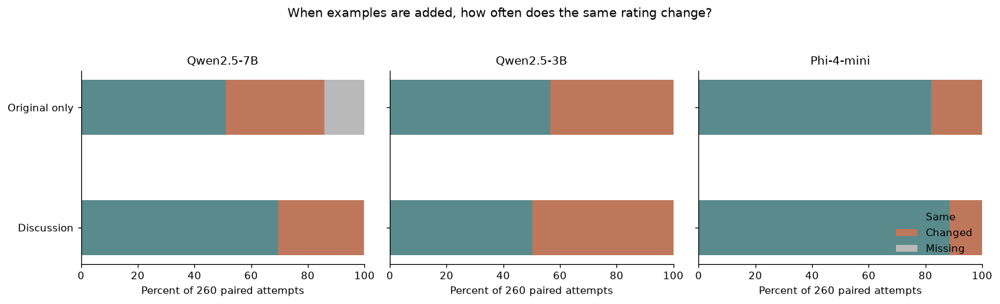

transition,model,condition,same,changed,missing
0,Phi-4-mini,discussion context,230,30,0
1,Phi-4-mini,no context,213,47,0
2,Qwen2.5-3B,discussion context,131,129,0
3,Qwen2.5-3B,no context,147,113,0
4,Qwen2.5-7B,discussion context,181,78,1
5,Qwen2.5-7B,no context,133,90,37


In [17]:
shot_rows=[]
for model,cond,name in product(MODELS,CONTEXTS,NAMES):
    z=W[(model,"zero-shot",cond,name)]
    f=W[(model,"five-shot",cond,name)]
    for k in IDS:
        a,b=z.loc[k],f.loc[k]
        shot_rows.append({"model":model,"condition":cond,"annotator":name,"id":k,
                          "zero":a,"five":b,"transition":"missing" if pd.isna(a) or pd.isna(b)
                          else "same" if a==b else "changed"})
shot_df=pd.DataFrame(shot_rows);shot_df.to_csv(TABLE/"fewshot_transitions.csv",index=False)
few=shot_df.groupby(["model","condition","transition"]).size().unstack(fill_value=0)
for c in ["same","changed","missing"]:
    if c not in few:few[c]=0
few=few[["same","changed","missing"]].reset_index()
fig,axs=plt.subplots(1,3,figsize=(13.3,3.8),sharey=True)
for ax,model in zip(axs,MODELS):
    sub=few[few.model==model].set_index("condition").reindex(CONTEXTS)
    left=np.zeros(2)
    for col,color in [("same","#598b8c"),("changed","#bf775b"),("missing","#b9b9b9")]:
        vals=sub[col].to_numpy()/260*100
        ax.barh(np.arange(2),vals,left=left,color=color,height=.46,label=col.capitalize())
        left+=vals
    ax.set(title=model,yticks=[0,1],yticklabels=["Original only","Discussion"],
           xlim=(0,100),xlabel="Percent of 260 paired attempts")
    ax.invert_yaxis()
axs[-1].legend(frameon=False,loc="lower right")
fig.suptitle("When examples are added, how often does the same rating change?",y=1.045)
fig.tight_layout();fig.savefig(FIG/"07_fewshot_changes.png",bbox_inches="tight");plt.show()
display(few)

## Are the persona descriptions producing different decisions?

Every pair of annotators is compared within the same model, context and prompting condition. With 13 annotators there are **78 distinct pairs**. The matrices always use the identical persona order; the diagonal shows rating availability, not a claim of independent agreement with oneself. High agreement can reflect shared class preferences rather than faithful human annotation. The exported table also measures pairs that differ in only one attribute.

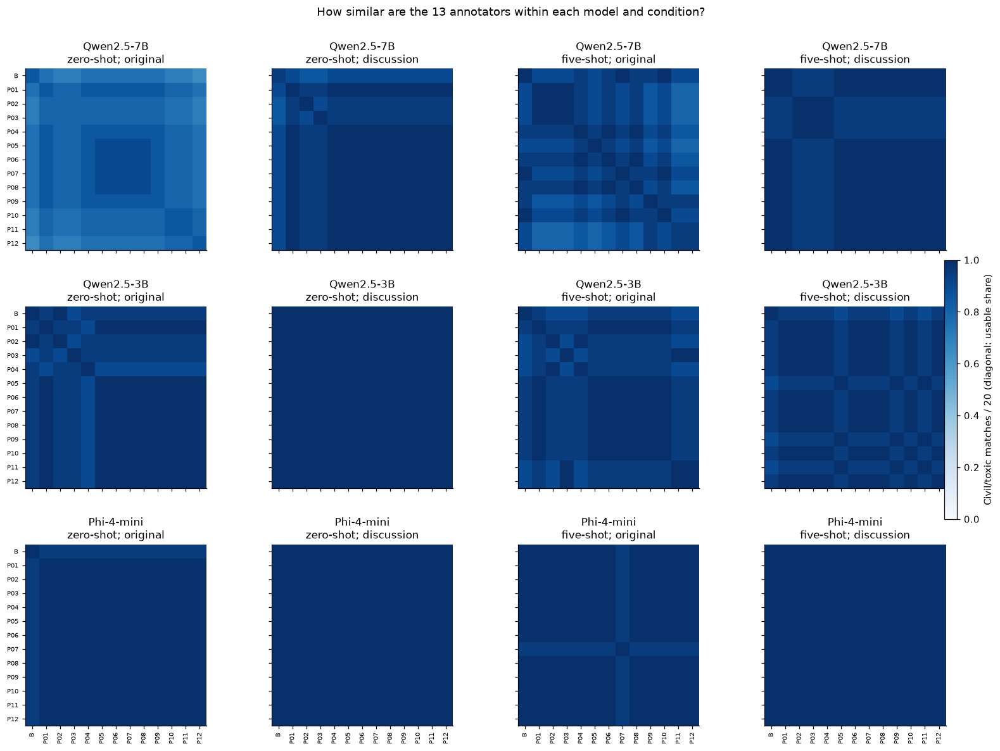

,model,prompting,condition,binary_all,exact_all,binary_valid,mean_valid_pairs
0,Qwen2.5-7B,zero-shot,no context,0.796795,0.739103,0.958038,16.628205
1,Qwen2.5-7B,zero-shot,discussion context,0.969231,0.875641,0.976451,19.846154
2,Qwen2.5-7B,five-shot,no context,0.912179,0.858333,0.925506,19.705128
3,Qwen2.5-7B,five-shot,discussion context,0.980769,0.871795,0.980769,20.000000
4,Qwen2.5-3B,zero-shot,no context,0.966667,0.816667,0.966667,20.000000
5,Qwen2.5-3B,zero-shot,discussion context,1.000000,0.976923,1.000000,20.000000
6,Qwen2.5-3B,five-shot,no context,0.958974,0.957692,0.958974,20.000000
7,Qwen2.5-3B,five-shot,discussion context,0.973077,0.900000,0.973077,20.000000
8,Phi-4-mini,zero-shot,no context,0.992308,0.914103,0.992308,20.000000
9,Phi-4-mini,zero-shot,discussion context,1.000000,0.969231,1.000000,20.000000


,model,prompting,condition,attribute,n_persona_pairs,mean_exact_disagreement
0,Qwen2.5-7B,zero-shot,no context,gender,6,0.183333
1,Qwen2.5-7B,zero-shot,no context,age_range,6,0.166667
2,Qwen2.5-7B,zero-shot,no context,political_outlook,12,0.283333
3,Qwen2.5-7B,zero-shot,discussion context,gender,6,0.066667
4,Qwen2.5-7B,zero-shot,discussion context,age_range,6,0.066667
5,Qwen2.5-7B,zero-shot,discussion context,political_outlook,12,0.116667
6,Qwen2.5-7B,five-shot,no context,gender,6,0.050000
7,Qwen2.5-7B,five-shot,no context,age_range,6,0.058333
8,Qwen2.5-7B,five-shot,no context,political_outlook,12,0.183333
9,Qwen2.5-7B,five-shot,discussion context,gender,6,0.033333


In [18]:
pair_rows=[]
for model,shot,cond in product(MODELS,PROMPTS,CONTEXTS):
    for a,b in combinations(NAMES,2):
        pair_rows.append({"model":model,"prompting":shot,"condition":cond,
                          "left":a,"right":b,**both_agreements(W[(model,shot,cond,a)],W[(model,shot,cond,b)])})
pairs=pd.DataFrame(pair_rows)
pairs.to_csv(TABLE/"pairwise_persona_agreement.csv",index=False)
means=pairs.groupby(["model","prompting","condition"],sort=False).agg(
    binary_all=("binary_all","mean"),exact_all=("exact_all","mean"),
    binary_valid=("binary_valid","mean"),mean_valid_pairs=("usable_pairs","mean")).reset_index()
means.to_csv(TABLE/"mean_pairwise_agreement.csv",index=False)
fig,axs=plt.subplots(3,4,figsize=(16,11.1),sharex=True,sharey=True)
for i,model in enumerate(MODELS):
    for j,(shot,cond) in enumerate(product(PROMPTS,CONTEXTS)):
        matrix=np.zeros((13,13))
        for k,name in enumerate(NAMES):
            matrix[k,k]=W[(model,shot,cond,name)].notna().mean()
        sub=pairs[(pairs.model==model)&(pairs.prompting==shot)&(pairs.condition==cond)]
        for r in sub.itertuples():
            ia,ib=NAMES.index(r.left),NAMES.index(r.right)
            matrix[ia,ib]=matrix[ib,ia]=r.binary_all
        ax=axs[i,j];im=ax.imshow(matrix,cmap="Blues",vmin=0,vmax=1,aspect="equal")
        ax.set(title=f"{model}\n{shot}; {'original' if cond=='no context' else 'discussion'}",
               xticks=range(13),xticklabels=[CODE[x] for x in NAMES],
               yticks=range(13),yticklabels=[CODE[x] for x in NAMES])
        ax.tick_params(axis="x",rotation=90,labelsize=6.5)
        ax.tick_params(axis="y",labelsize=6.5)
fig.colorbar(im,ax=axs.ravel().tolist(),fraction=.015,pad=.01,label="Civil/toxic matches / 20 (diagonal: usable share)")
fig.suptitle("How similar are the 13 annotators within each model and condition?",y=.99)
fig.subplots_adjust(left=.05,right=.89,top=.91,bottom=.06,hspace=.31,wspace=.25)
fig.savefig(FIG/"08_persona_pair_heatmaps.png",bbox_inches="tight");plt.show()
display(means)

attribute_rows=[]
for model,shot,cond in product(MODELS,PROMPTS,CONTEXTS):
    for attr in ["gender","age_range","political_outlook"]:
        samples=[]
        for a,b in combinations(list(PERSONAS)[1:],2):
            diff=[field for field in ["gender","age_range","political_outlook"] if PERSONAS[a][field]!=PERSONAS[b][field]]
            if diff==[attr]:
                samples.append(both_agreements(W[(model,shot,cond,a)],W[(model,shot,cond,b)])["exact_all"])
        attribute_rows.append({"model":model,"prompting":shot,"condition":cond,
                               "attribute":attr,"n_persona_pairs":len(samples),
                               "mean_exact_disagreement":1-np.mean(samples) if samples else np.nan})
attr_df=pd.DataFrame(attribute_rows)
attr_df.to_csv(TABLE/"single_attribute_contrasts.csv",index=False)
display(attr_df)

### Chance-corrected annotator agreement

Percentage agreement measures how often annotators assign identical labels, but it does not account for agreement expected from their label distributions. This distinction matters here because some models strongly favor particular toxicity categories, potentially producing high agreement even when their judgments are poorly calibrated.

As a supplementary analysis, I calculate **Cohen's kappa** for binary civil/toxic classifications and **quadratically weighted kappa** for the ordinal 1–5 toxicity ratings. Both measures are computed on matched items with usable ratings. Unlike the primary assignment metrics, these measures adjust for chance agreement; however, they can be unstable when one category dominates or when only a few observations are available. Undefined values are reported rather than replaced with zero.

In [27]:
from sklearn.metrics import cohen_kappa_score
import warnings

def compute_kappa(left, right):
    # compare only items with usable ratings from both annotators
    paired = pd.DataFrame({
        "left": left.reindex(IDS),
        "right": right.reindex(IDS)
    }).dropna()

    if len(paired) < 2:
        return np.nan, np.nan

    a = paired["left"].astype(int)
    b = paired["right"].astype(int)

    # binary agreement: civil (0) or toxic (1)
    a_binary = (a >= 3).astype(int)
    b_binary = (b >= 3).astype(int)

    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)

        binary_kappa = cohen_kappa_score(
            a_binary, b_binary, labels=[0, 1]
        )

        weighted_kappa = cohen_kappa_score(
            a, b,
            labels=[1, 2, 3, 4, 5],
            weights="quadratic"
        )

    return binary_kappa, weighted_kappa


# compare each persona and baseline with the human reference
human_kappa = []

for model, shot, condition, annotator in product(
    MODELS, PROMPTS, CONTEXTS, NAMES
):
    binary_k, weighted_k = compute_kappa(
        REF, W[(model, shot, condition, annotator)]
    )

    human_kappa.append({
        "model": model,
        "prompting": shot,
        "condition": condition,
        "annotator": annotator,
        "binary_kappa": binary_k,
        "weighted_kappa": weighted_k
    })

human_kappa = pd.DataFrame(human_kappa)


# compare all pairs of model personas within each condition
persona_kappa = []

for model, shot, condition in product(
    MODELS, PROMPTS, CONTEXTS
):
    for left, right in combinations(NAMES, 2):
        binary_k, weighted_k = compute_kappa(
            W[(model, shot, condition, left)],
            W[(model, shot, condition, right)]
        )

        persona_kappa.append({
            "model": model,
            "prompting": shot,
            "condition": condition,
            "left": left,
            "right": right,
            "binary_kappa": binary_k,
            "weighted_kappa": weighted_k
        })

persona_kappa = pd.DataFrame(persona_kappa)


# report averages alongside the primary agreement statistics
print("Mean agreement with the human reference")
display(
    human_kappa.groupby(
        ["model", "prompting", "condition"]
    )[["binary_kappa", "weighted_kappa"]]
    .mean()
    .round(3)
)

print("Mean agreement between model annotators")
display(
    persona_kappa.groupby(
        ["model", "prompting", "condition"]
    )[["binary_kappa", "weighted_kappa"]]
    .mean()
    .round(3)
)

# keep the full comparisons for inspection and presentation
human_kappa.to_csv(
    TABLE / "human_cohen_kappa.csv", index=False
)
persona_kappa.to_csv(
    TABLE / "persona_cohen_kappa.csv", index=False
)

/opt/george-data/Documents/uni/practical-ds/.venv/lib/python3.12/site-packages/sklearn/utils/_param_validation.py:218: UndefinedMetricWarning: `y1`, `y2` and `labels` have only one label in common. `cohen_kappa_score` is undefined and set to the value defined by the the `replace_undefined_by` param, which is set to nan.
  return func(*args, **kwargs)
/opt/george-data/Documents/uni/practical-ds/.venv/lib/python3.12/site-packages/sklearn/utils/_param_validation.py:218: UndefinedMetricWarning: `y1`, `y2` and `labels` have only one label in common. `cohen_kappa_score` is undefined and set to the value defined by the the `replace_undefined_by` param, which is set to nan.
  return func(*args, **kwargs)
/opt/george-data/Documents/uni/practical-ds/.venv/lib/python3.12/site-packages/sklearn/utils/_param_validation.py:218: UndefinedMetricWarning: `y1`, `y2` and `labels` have only one label in common. `cohen_kappa_score` is undefined and set to the value defined by the the `replace_undefined_by` 

Mean agreement with the human reference


/opt/george-data/Documents/uni/practical-ds/.venv/lib/python3.12/site-packages/sklearn/utils/_param_validation.py:218: UndefinedMetricWarning: `y1`, `y2` and `labels` have only one label in common. `cohen_kappa_score` is undefined and set to the value defined by the the `replace_undefined_by` param, which is set to nan.
  return func(*args, **kwargs)
/opt/george-data/Documents/uni/practical-ds/.venv/lib/python3.12/site-packages/sklearn/utils/_param_validation.py:218: UndefinedMetricWarning: `y1`, `y2` and `labels` have only one label in common. `cohen_kappa_score` is undefined and set to the value defined by the the `replace_undefined_by` param, which is set to nan.
  return func(*args, **kwargs)
/opt/george-data/Documents/uni/practical-ds/.venv/lib/python3.12/site-packages/sklearn/utils/_param_validation.py:218: UndefinedMetricWarning: `y1`, `y2` and `labels` have only one label in common. `cohen_kappa_score` is undefined and set to the value defined by the the `replace_undefined_by` 

binary_kappa  weighted_kappa
model      prompting condition                                       
Phi-4-mini five-shot discussion context         0.000           0.070
                     no context                 0.230           0.277
           zero-shot discussion context         0.000           0.104
                     no context                 0.130           0.233
Qwen2.5-3B five-shot discussion context        -0.030           0.169
                     no context                 0.257           0.549
           zero-shot discussion context         0.000           0.016
                     no context                 0.111           0.193
Qwen2.5-7B five-shot discussion context         0.322           0.556
                     no context                 0.518           0.571
           zero-shot discussion context         0.123           0.332
                     no context                 0.090           0.335

Mean agreement between model annotators


binary_kappa  weighted_kappa
model      prompting condition                                       
Phi-4-mini five-shot discussion context           NaN           1.000
                     no context                 0.945           0.939
           zero-shot discussion context           NaN           0.922
                     no context                 0.945           0.894
Qwen2.5-3B five-shot discussion context         0.068           0.792
                     no context                 0.784           0.938
           zero-shot discussion context           NaN           0.770
                     no context                 0.545           0.676
Qwen2.5-7B five-shot discussion context         0.962           0.950
                     no context                 0.848           0.904
           zero-shot discussion context         0.951           0.917
                     no context                 0.878           0.933

## Do different models reach the same decisions?

The three model pairs are compared on exactly matched **item × persona** observations. The denominator is 260 for each context-and-prompt condition. The second percentage conditions on both models having readable ratings. This is the most direct way to separate cross-model differences from format availability. The Qwen 3B versus 7B comparison additionally tests whether model size changes ratings within the same family.

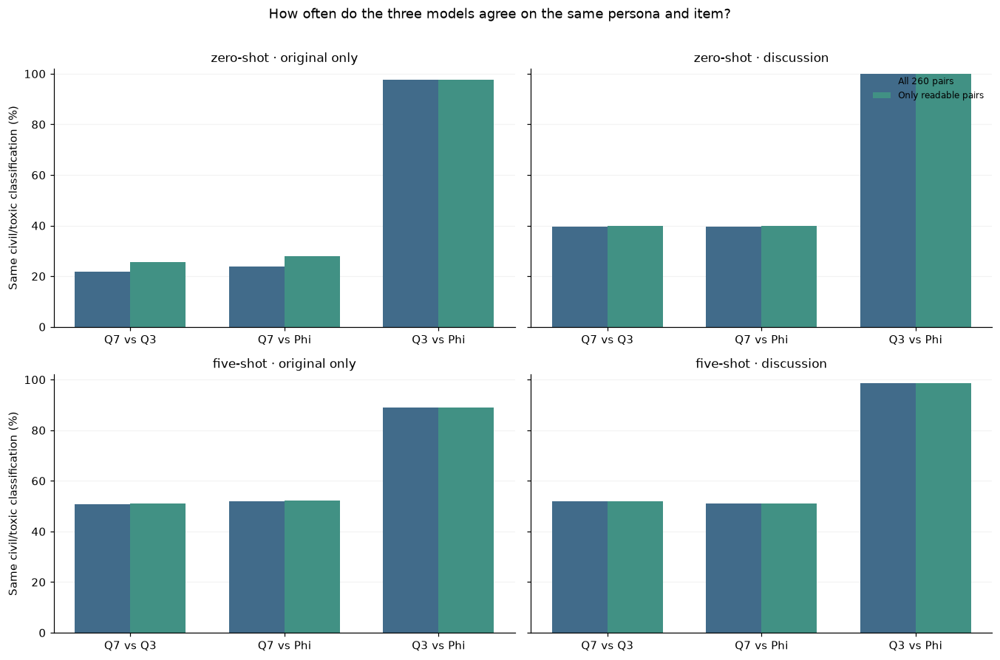

,prompting,condition,model_a,model_b,binary_matches,exact_matches,usable_pairs,binary_all,exact_all,binary_valid,exact_valid
0,zero-shot,no context,Qwen2.5-7B,Qwen2.5-3B,57,33,223,0.219231,0.126923,0.255605,0.147982
1,zero-shot,no context,Qwen2.5-7B,Phi-4-mini,62,13,223,0.238462,0.050000,0.278027,0.058296
2,zero-shot,no context,Qwen2.5-3B,Phi-4-mini,254,55,260,0.976923,0.211538,0.976923,0.211538
3,zero-shot,discussion context,Qwen2.5-7B,Qwen2.5-3B,103,0,259,0.396154,0.000000,0.397683,0.000000
4,zero-shot,discussion context,Qwen2.5-7B,Phi-4-mini,103,25,259,0.396154,0.096154,0.397683,0.096525
5,zero-shot,discussion context,Qwen2.5-3B,Phi-4-mini,260,43,260,1.000000,0.165385,1.000000,0.165385
6,five-shot,no context,Qwen2.5-7B,Qwen2.5-3B,132,97,258,0.507692,0.373077,0.511628,0.375969
7,five-shot,no context,Qwen2.5-7B,Phi-4-mini,135,28,258,0.519231,0.107692,0.523256,0.108527
8,five-shot,no context,Qwen2.5-3B,Phi-4-mini,231,15,260,0.888462,0.057692,0.888462,0.057692
9,five-shot,discussion context,Qwen2.5-7B,Qwen2.5-3B,135,35,260,0.519231,0.134615,0.519231,0.134615


In [19]:
cross=[]
for shot,cond,a,b in product(PROMPTS,CONTEXTS,MODELS,MODELS):
    if MODELS.index(a)>=MODELS.index(b):continue
    for name in NAMES:
        cross.append({"prompting":shot,"condition":cond,"model_a":a,"model_b":b,
                      "annotator":name, **both_agreements(W[(a,shot,cond,name)],W[(b,shot,cond,name)])})
cross_df=pd.DataFrame(cross)
cross_df.to_csv(TABLE/"cross_model_by_persona.csv",index=False)
rolled=cross_df.groupby(["prompting","condition","model_a","model_b"],sort=False).agg(
    binary_matches=("binary_matches","sum"),exact_matches=("exact_matches","sum"),
    usable_pairs=("usable_pairs","sum")).reset_index()
rolled["binary_all"]=rolled.binary_matches/260
rolled["exact_all"]=rolled.exact_matches/260
rolled["binary_valid"]=rolled.binary_matches/rolled.usable_pairs.replace(0,np.nan)
rolled["exact_valid"]=rolled.exact_matches/rolled.usable_pairs.replace(0,np.nan)
rolled.to_csv(TABLE/"cross_model_summary.csv",index=False)
pair_order=list(combinations(MODELS,2))
fig,axs=plt.subplots(2,2,figsize=(12.4,8.0),sharey=True)
for i,shot in enumerate(PROMPTS):
 for j,cond in enumerate(CONTEXTS):
    ax=axs[i,j];part=rolled[(rolled.prompting==shot)&(rolled.condition==cond)]
    xx=np.arange(3)
    for off,col,color,label in [(-.18,"binary_all","#416b8a","All 260 pairs"),
                                (.18,"binary_valid","#419184","Only readable pairs")]:
        vals=[part[(part.model_a==a)&(part.model_b==b)].iloc[0][col]*100 for a,b in pair_order]
        ax.bar(xx+off,vals,.36,color=color,label=label)
    ax.set(title=f"{shot} · {'original only' if cond=='no context' else 'discussion'}",
           xticks=xx,xticklabels=["Q7 vs Q3","Q7 vs Phi","Q3 vs Phi"],ylim=(0,102))
    ax.grid(axis="y",alpha=.15);ax.set_axisbelow(True)
    if j==0:ax.set_ylabel("Same civil/toxic classification (%)")
axs[0,1].legend(frameon=False,fontsize=8,loc="upper right")
fig.suptitle("How often do the three models agree on the same persona and item?",y=1.01)
fig.tight_layout();fig.savefig(FIG/"09_cross_model_agreement.png",bbox_inches="tight");plt.show()
display(rolled)

## Interpretation

The results should be read in this order: whether models give readable ratings, whether they use the scale, how close they are to my reference, and only then whether discussion context or examples alter the predictions. The charts cannot establish causal demographic effects in real people; the personas are prompt descriptions and all items share one human reference.

One item is five percentage points of a 20-item, single-persona agreement score. Some differences will therefore be small in absolute counts, and the four model × context × prompting cells are exploratory rather than independent human samples. High agreement between synthetic personas is not sufficient evidence of accuracy if most predictions fall in one class.

In [20]:
notes=[]
for model in MODELS:
    v=validity[validity.model==model]
    zero=v[v.prompting.eq("zero-shot")].rating_pct.mean()
    fewv=v[v.prompting.eq("five-shot")].rating_pct.mean()
    sev=A[(A.model==model)&A.rating.notna()]
    modes=sev.rating.value_counts()
    mode=int(modes.index[0]) if len(modes) else None
    mode_share=modes.iloc[0]/len(sev) if len(sev) else np.nan
    h=summary[summary.model==model]
    z=h[h.prompting.eq("zero-shot")].binary_agreement.mean()
    f=h[h.prompting.eq("five-shot")].binary_agreement.mean()
    for shot in PROMPTS:
        ct=trans_summary[(trans_summary.model==model)&(trans_summary.prompting==shot)].iloc[0]
        matched=int(ct.lower+ct.same+ct.higher)
        notes.append(f"**{model}, {shot}:** discussion changes {int(ct.lower+ct.higher)}/{matched} "
                     f"readable paired ratings; {int(ct.unmatched)}/260 comparisons lack at least one rating."
                     if matched else f"**{model}, {shot}:** no readable paired comparisons.")
    notes.insert(len(notes)-2,
        f"**{model}:** readable numeric ratings average {zero:.1f}% in zero-shot and {fewv:.1f}% "
        f"in five-shot across contexts. The most frequent readable score is {mode} ({mode_share:.1%} of "
        f"readable scores). Mean binary agreement with the human across personas and contexts "
        f"moves from {z:.1%} to {f:.1%} when examples are added.")
display(Markdown("\n\n".join(notes)))
print("\nMean inter-persona agreement (all 20 items as denominator):")
display(means[["model","prompting","condition","binary_all","exact_all","mean_valid_pairs"]])
print("\nHighest ranking personas under each condition:")
display(closest)
print("\nInterpretation: check whether exact-severity agreement follows binary agreement, "
      "and whether compliance changes explain apparent gains or losses.")

**Qwen2.5-7B:** readable numeric ratings average 92.7% in zero-shot and 99.6% in five-shot across contexts. The most frequent readable score is 2 (31.7% of readable scores). Mean binary agreement with the human across personas and contexts moves from 47.5% to 70.6% when examples are added.

**Qwen2.5-7B, zero-shot:** discussion changes 116/222 readable paired ratings; 38/260 comparisons lack at least one rating.

**Qwen2.5-7B, five-shot:** discussion changes 100/258 readable paired ratings; 2/260 comparisons lack at least one rating.

**Qwen2.5-3B:** readable numeric ratings average 100.0% in zero-shot and 100.0% in five-shot across contexts. The most frequent readable score is 5 (54.0% of readable scores). Mean binary agreement with the human across personas and contexts moves from 57.5% to 59.6% when examples are added.

**Qwen2.5-3B, zero-shot:** discussion changes 114/260 readable paired ratings; 0/260 comparisons lack at least one rating.

**Qwen2.5-3B, five-shot:** discussion changes 119/260 readable paired ratings; 0/260 comparisons lack at least one rating.

**Phi-4-mini:** readable numeric ratings average 100.0% in zero-shot and 100.0% in five-shot across contexts. The most frequent readable score is 4 (83.8% of readable scores). Mean binary agreement with the human across personas and contexts moves from 57.5% to 59.8% when examples are added.

**Phi-4-mini, zero-shot:** discussion changes 63/260 readable paired ratings; 0/260 comparisons lack at least one rating.

**Phi-4-mini, five-shot:** discussion changes 27/260 readable paired ratings; 0/260 comparisons lack at least one rating.


Mean inter-persona agreement (all 20 items as denominator):


,model,prompting,condition,binary_all,exact_all,mean_valid_pairs
0,Qwen2.5-7B,zero-shot,no context,0.796795,0.739103,16.628205
1,Qwen2.5-7B,zero-shot,discussion context,0.969231,0.875641,19.846154
2,Qwen2.5-7B,five-shot,no context,0.912179,0.858333,19.705128
3,Qwen2.5-7B,five-shot,discussion context,0.980769,0.871795,20.000000
4,Qwen2.5-3B,zero-shot,no context,0.966667,0.816667,20.000000
5,Qwen2.5-3B,zero-shot,discussion context,1.000000,0.976923,20.000000
6,Qwen2.5-3B,five-shot,no context,0.958974,0.957692,20.000000
7,Qwen2.5-3B,five-shot,discussion context,0.973077,0.900000,20.000000
8,Phi-4-mini,zero-shot,no context,0.992308,0.914103,20.000000
9,Phi-4-mini,zero-shot,discussion context,1.000000,0.969231,20.000000



Highest ranking personas under each condition:


,model,prompting,condition,closest_persona,binary_matches_of_20,exact_matches_of_20,baseline_binary_matches_of_20,baseline_exact_matches_of_20
0,Qwen2.5-7B,zero-shot,no context,centrist | 18–29 | woman,9,5,10,6
1,Qwen2.5-7B,zero-shot,discussion context,progressive | 55–70 | woman,12,3,11,5
2,Qwen2.5-7B,five-shot,no context,centrist | 18–29 | woman,17,10,15,8
3,Qwen2.5-7B,five-shot,discussion context,progressive | 18–29 | man,14,5,13,5
4,Qwen2.5-3B,zero-shot,no context,progressive | 55–70 | woman,13,2,11,2
5,Qwen2.5-3B,zero-shot,discussion context,conservative | 18–29 | man,11,2,11,1
6,Qwen2.5-3B,five-shot,no context,conservative | 55–70 | woman,14,7,14,7
7,Qwen2.5-3B,five-shot,discussion context,progressive | 18–29 | woman,11,4,10,3
8,Phi-4-mini,zero-shot,no context,centrist | 18–29 | woman,12,5,13,5
9,Phi-4-mini,zero-shot,discussion context,progressive | 18–29 | woman,11,5,11,5



Interpretation: check whether exact-severity agreement follows binary agreement, and whether compliance changes explain apparent gains or losses.


## Saved records and inspectable annotations

This notebook deliberately does not print 3,120 full prompts in the default view. The complete results can be expanded below, including each item, persona, response, rating, evidence issue and the serialized prompt. All attempts, as well as the full conversations, are also exported to the new directory. Nothing is imputed for missing ratings.

In [21]:
for model in MODELS:
  for shot in PROMPTS:
    for cond in CONTEXTS:
      part=A[(A.model==model)&(A.prompting==shot)&(A.condition==cond)].sort_values(["annotator","id"])
      label=f"{model} · {shot} · {cond} — all {len(part)} annotation attempts (expand)"
      cols=["annotator","id","text","rating","label","evidence","rating_status",
            "evidence_status","format_status","raw_answer","prompt","error"]
      display(HTML(f'<details><summary>{label}</summary><div style="max-height:440px;overflow:auto">'+
                   part[cols].to_html(index=False,escape=True)+'</div></details>'))
print("All annotation tables and conversations are also saved as CSV / JSONL files.")

annotator,id,text,rating,label,evidence,rating_status,evidence_status,format_status,raw_answer,prompt,error
baseline,1,Its Sussex Dr. you idiot and Harper lived prior to the election.,2.0,civil,you idiot,usable,unexpected civil evidence,standard,2 | you idiot,"{""persona"": {}, ""instructions"": ""Rate the toxicity of the ORIGINAL COMMENT, not the discussion about it. Judge the language rather than political agreement. 1 = civil or respectful disagreement; 2 = mildly rude or dismissive without direct abuse; 3 = clear insult or hostile personal remark; 4 = strongly degrading or repeated abuse; 5 = explicit threat, wish of serious harm, or extreme targeted abuse. Choose the rating before selecting evidence. Return a single line: NUMBER | EVIDENCE. NUMBER is an integer 1 to 5. For 1 or 2, use not needed as evidence. For 3 to 5, copy one short continuous passage verbatim from the ORIGINAL COMMENT. No explanation, introductory text, paraphrase or extra lines."", ""context"": ""You are annotating an original comment from a news-site discussion."", ""system_prompt"": ""{\""context\"": \""You are annotating an original comment from a news-site discussion.\"", \""instructions\"": \""Rate the toxicity of the ORIGINAL COMMENT, not the discussion about it. Judge the language rather than political agreement. 1 = civil or respectful disagreement; 2 = mildly rude or dismissive without direct abuse; 3 = clear insult or hostile personal remark; 4 = strongly degrading or repeated abuse; 5 = explicit threat, wish of serious harm, or extreme targeted abuse. Choose the rating before selecting evidence. Return a single line: NUMBER | EVIDENCE. NUMBER is an integer 1 to 5. For 1 or 2, use not needed as evidence. For 3 to 5, copy one short continuous passage verbatim from the ORIGINAL COMMENT. No explanation, introductory text, paraphrase or extra lines.\"", \""type\"": \""annotator\"", \""persona\"": {}}"", ""user_prompt"": ""{\""context\"": \""You are annotating an original comment from a news-site discussion.\"", \""instructions\"": \""Rate the toxicity of the ORIGINAL COMMENT, not the discussion about it. Judge the language rather than political agreement. 1 = civil or respectful disagreement; 2 = mildly rude or dismissive without direct abuse; 3 = clear insult or hostile personal remark; 4 = strongly degrading or repeated abuse; 5 = explicit threat, wish of serious harm, or extreme targeted abuse. Choose the rating before selecting evidence. Return a single line: NUMBER | EVIDENCE. NUMBER is an integer 1 to 5. For 1 or 2, use not needed as evidence. For 3 to 5, copy one short continuous passage verbatim from the ORIGINAL COMMENT. No explanation, introductory text, paraphrase or extra lines.\"", \""type\"": \""annotator\"", \""persona\"": {}}""}",
baseline,2,The republicans have the White House and the majority of the senate and House. That being said even a snail has made more progress than the idiot in chief and his circus of clowns. The Chump train is heading for certain derailment and the Chumpsters are stuck on it because they have s**t for brains.,2.0,civil,The Chump train is heading for certain derailment and the Chumpsters are stuck on it because they have s**t for brains.,usable,unexpected civil evidence,standard,"2 | ""The Chump train is heading for certain derailment and the Chumpsters are stuck on it because they have s**t for brains.""","{""persona"": {}, ""instructions"": ""Rate the toxicity of the ORIGINAL COMMENT, not the discussion about it. Judge the language rather than political agreement. 1 = civil or respectful disagreement; 2 = mildly rude or dismissive without direct abuse; 3 = clear insult or hostile personal remark; 4 = strongly degrading or repeated abuse; 5 = explicit threat, wish of serious harm, or extreme targeted abuse. Choose the rating before selecting evidence. Return a single line: NUMBER | EVIDENCE. NUMBER is an integer 1 to 5. For 1 or 2, use not needed as evidence. For 3 to 5, copy one short continuous passa

annotator,id,text,rating,label,evidence,rating_status,evidence_status,format_status,raw_answer,prompt,error
baseline,1,Its Sussex Dr. you idiot and Harper lived prior to the election.,3.0,toxic,idiot,usable,compliant,standard,3 | idiot,"{""persona"": {}, ""instructions"": ""Rate the toxicity of the ORIGINAL COMMENT, not the discussion about it. Judge the language rather than political agreement. 1 = civil or respectful disagreement; 2 = mildly rude or dismissive without direct abuse; 3 = clear insult or hostile personal remark; 4 = strongly degrading or repeated abuse; 5 = explicit threat, wish of serious harm, or extreme targeted abuse. Choose the rating before selecting evidence. Return a single line: NUMBER | EVIDENCE. NUMBER is an integer 1 to 5. For 1 or 2, use not needed as evidence. For 3 to 5, copy one short continuous passage verbatim from the ORIGINAL COMMENT. No explanation, introductory text, paraphrase or extra lines.\n\nExamples (different from the comments you will rate):\nComment: I disagree with the proposal, but appreciate the explanation.\nAnswer: 1 | not needed\nComment: That is a pretty silly suggestion.\nAnswer: 2 | not needed\nComment: You are an idiot.\nAnswer: 3 | idiot\nComment: You're a worthless fraud and an embarrassment.\nAnswer: 4 | worthless fraud\nComment: I will hurt you if you say that again.\nAnswer: 5 | I will hurt you\n\nNow rate the new original comment."", ""context"": ""You are annotating an original comment from a news-site discussion."", ""system_prompt"": ""{\""context\"": \""You are annotating an original comment from a news-site discussion.\"", \""instructions\"": \""Rate the toxicity of the ORIGINAL COMMENT, not the discussion about it. Judge the language rather than political agreement. 1 = civil or respectful disagreement; 2 = mildly rude or dismissive without direct abuse; 3 = clear insult or hostile personal remark; 4 = strongly degrading or repeated abuse; 5 = explicit threat, wish of serious harm, or extreme targeted abuse. Choose the rating before selecting evidence. Return a single line: NUMBER | EVIDENCE. NUMBER is an integer 1 to 5. For 1 or 2, use not needed as evidence. For 3 to 5, copy one short continuous passage verbatim from the ORIGINAL COMMENT. No explanation, introductory text, paraphrase or extra lines.\\n\\nExamples (different from the comments you will rate):\\nComment: I disagree with the proposal, but appreciate the explanation.\\nAnswer: 1 | not needed\\nComment: That is a pretty silly suggestion.\\nAnswer: 2 | not needed\\nComment: You are an idiot.\\nAnswer: 3 | idiot\\nComment: You're a worthless fraud and an embarrassment.\\nAnswer: 4 | worthless fraud\\nComment: I will hurt you if you say that again.\\nAnswer: 5 | I will hurt you\\n\\nNow rate the new original comment.\"", \""type\"": \""annotator\"", \""persona\"": {}}"", ""user_prompt"": ""{\""context\"": \""You are annotating an original comment from a news-site discussion.\"", \""instructions\"": \""Rate the toxicity of the ORIGINAL COMMENT, not the discussion about it. Judge the language rather than political agreement. 1 = civil or respectful disagreement; 2 = mildly rude or dismissive without direct abuse; 3 = clear insult or hostile personal remark; 4 = strongly degrading or repeated abuse; 5 = explicit threat, wish of serious harm, or extreme targeted abuse. Choose the rating before selecting evidence. Return a single line: NUMBER | EVIDENCE. NUMBER is an integer 1 to 5. For 1 or 2, use not needed as evidence. For 3 to 5, copy one short continuous passage verbatim from the ORIGINAL COMMENT. No explanation, introductory text, paraphrase or extra lines.\\n\\nExamples (different from the comments you will rate):\\nComment: I disagree with the proposal, but appreciate the explanation.\\nAnswer: 1 | not needed\\nComment: That is a pretty silly suggestion.\\nAnswer: 2 | not needed\\nComment: You are an idiot.\\nAnswer: 3 | idiot\\nComment: You're a worthless fraud and an embarrassment.\\nAnswer: 4 

annotator,id,text,rating,label,evidence,rating_status,evidence_status,format_status,raw_answer,prompt,error
baseline,1,Its Sussex Dr. you idiot and Harper lived prior to the election.,3.0,toxic,Its Sussex Dr. you idiot and Harper lived prior to the election.,usable,compliant,standard,3 | Its Sussex Dr. you idiot and Harper lived prior to the election.,"{""persona"": {}, ""instructions"": ""Rate the toxicity of the ORIGINAL COMMENT, not the discussion about it. Judge the language rather than political agreement. 1 = civil or respectful disagreement; 2 = mildly rude or dismissive without direct abuse; 3 = clear insult or hostile personal remark; 4 = strongly degrading or repeated abuse; 5 = explicit threat, wish of serious harm, or extreme targeted abuse. Choose the rating before selecting evidence. Return a single line: NUMBER | EVIDENCE. NUMBER is an integer 1 to 5. For 1 or 2, use not needed as evidence. For 3 to 5, copy one short continuous passage verbatim from the ORIGINAL COMMENT. No explanation, introductory text, paraphrase or extra lines."", ""context"": ""You are annotating an original comment from a news-site discussion."", ""system_prompt"": ""{\""context\"": \""You are annotating an original comment from a news-site discussion.\"", \""instructions\"": \""Rate the toxicity of the ORIGINAL COMMENT, not the discussion about it. Judge the language rather than political agreement. 1 = civil or respectful disagreement; 2 = mildly rude or dismissive without direct abuse; 3 = clear insult or hostile personal remark; 4 = strongly degrading or repeated abuse; 5 = explicit threat, wish of serious harm, or extreme targeted abuse. Choose the rating before selecting evidence. Return a single line: NUMBER | EVIDENCE. NUMBER is an integer 1 to 5. For 1 or 2, use not needed as evidence. For 3 to 5, copy one short continuous passage verbatim from the ORIGINAL COMMENT. No explanation, introductory text, paraphrase or extra lines.\"", \""type\"": \""annotator\"", \""persona\"": {}}"", ""user_prompt"": ""{\""context\"": \""You are annotating an original comment from a news-site discussion.\"", \""instructions\"": \""Rate the toxicity of the ORIGINAL COMMENT, not the discussion about it. Judge the language rather than political agreement. 1 = civil or respectful disagreement; 2 = mildly rude or dismissive without direct abuse; 3 = clear insult or hostile personal remark; 4 = strongly degrading or repeated abuse; 5 = explicit threat, wish of serious harm, or extreme targeted abuse. Choose the rating before selecting evidence. Return a single line: NUMBER | EVIDENCE. NUMBER is an integer 1 to 5. For 1 or 2, use not needed as evidence. For 3 to 5, copy one short continuous passage verbatim from the ORIGINAL COMMENT. No explanation, introductory text, paraphrase or extra lines.\"", \""type\"": \""annotator\"", \""persona\"": {}}""}",
baseline,2,The republicans have the White House and the majority of the senate and House. That being said even a snail has made more progress than the idiot in chief and his circus of clowns. The Chump train is heading for certain derailment and the Chumpsters are stuck on it because they have s**t for brains.,5.0,toxic,The Chump train is heading for certain derailment and the Chumpsters are stuck on it because they have s**t for brains.,usable,compliant,standard,"5 | ""The Chump train is heading for certain derailment and the Chumpsters are stuck on it because they have s**t for brains.""","{""persona"": {}, ""instructions"": ""Rate the toxicity of the ORIGINAL COMMENT, not the discussion about it. Judge the language rather than political agreement. 1 = civil or respectful disagreement; 2 = mildly rude or dismissive without direct abuse; 3 = clear insult or hostile personal remark; 4 = strongly degrading or repeated abuse; 5 = explicit threat, wish of serious harm, or extreme targeted abuse. Choose the rating before selecting evidence. Return a single line: NUMBER | EVIDENCE. NUMBER is an integer 1 to 5. For 1

annotator,id,text,rating,label,evidence,rating_status,evidence_status,format_status,raw_answer,prompt,error
baseline,1,Its Sussex Dr. you idiot and Harper lived prior to the election.,3.0,toxic,idiot,usable,compliant,standard,3 | idiot,"{""persona"": {}, ""instructions"": ""Rate the toxicity of the ORIGINAL COMMENT, not the discussion about it. Judge the language rather than political agreement. 1 = civil or respectful disagreement; 2 = mildly rude or dismissive without direct abuse; 3 = clear insult or hostile personal remark; 4 = strongly degrading or repeated abuse; 5 = explicit threat, wish of serious harm, or extreme targeted abuse. Choose the rating before selecting evidence. Return a single line: NUMBER | EVIDENCE. NUMBER is an integer 1 to 5. For 1 or 2, use not needed as evidence. For 3 to 5, copy one short continuous passage verbatim from the ORIGINAL COMMENT. No explanation, introductory text, paraphrase or extra lines.\n\nExamples (different from the comments you will rate):\nComment: I disagree with the proposal, but appreciate the explanation.\nAnswer: 1 | not needed\nComment: That is a pretty silly suggestion.\nAnswer: 2 | not needed\nComment: You are an idiot.\nAnswer: 3 | idiot\nComment: You're a worthless fraud and an embarrassment.\nAnswer: 4 | worthless fraud\nComment: I will hurt you if you say that again.\nAnswer: 5 | I will hurt you\n\nNow rate the new original comment."", ""context"": ""You are annotating an original comment from a news-site discussion."", ""system_prompt"": ""{\""context\"": \""You are annotating an original comment from a news-site discussion.\"", \""instructions\"": \""Rate the toxicity of the ORIGINAL COMMENT, not the discussion about it. Judge the language rather than political agreement. 1 = civil or respectful disagreement; 2 = mildly rude or dismissive without direct abuse; 3 = clear insult or hostile personal remark; 4 = strongly degrading or repeated abuse; 5 = explicit threat, wish of serious harm, or extreme targeted abuse. Choose the rating before selecting evidence. Return a single line: NUMBER | EVIDENCE. NUMBER is an integer 1 to 5. For 1 or 2, use not needed as evidence. For 3 to 5, copy one short continuous passage verbatim from the ORIGINAL COMMENT. No explanation, introductory text, paraphrase or extra lines.\\n\\nExamples (different from the comments you will rate):\\nComment: I disagree with the proposal, but appreciate the explanation.\\nAnswer: 1 | not needed\\nComment: That is a pretty silly suggestion.\\nAnswer: 2 | not needed\\nComment: You are an idiot.\\nAnswer: 3 | idiot\\nComment: You're a worthless fraud and an embarrassment.\\nAnswer: 4 | worthless fraud\\nComment: I will hurt you if you say that again.\\nAnswer: 5 | I will hurt you\\n\\nNow rate the new original comment.\"", \""type\"": \""annotator\"", \""persona\"": {}}"", ""user_prompt"": ""{\""context\"": \""You are annotating an original comment from a news-site discussion.\"", \""instructions\"": \""Rate the toxicity of the ORIGINAL COMMENT, not the discussion about it. Judge the language rather than political agreement. 1 = civil or respectful disagreement; 2 = mildly rude or dismissive without direct abuse; 3 = clear insult or hostile personal remark; 4 = strongly degrading or repeated abuse; 5 = explicit threat, wish of serious harm, or extreme targeted abuse. Choose the rating before selecting evidence. Return a single line: NUMBER | EVIDENCE. NUMBER is an integer 1 to 5. For 1 or 2, use not needed as evidence. For 3 to 5, copy one short continuous passage verbatim from the ORIGINAL COMMENT. No explanation, introductory text, paraphrase or extra lines.\\n\\nExamples (different from the comments you will rate):\\nComment: I disagree with the proposal, but appreciate the explanation.\\nAnswer: 1 | not needed\\nComment: That is a pretty silly suggestion.\\nAnswer: 2 | not needed\\nComment: You are an idiot.\\nAnswer: 3 | idiot\\nComment: You're a worthless fraud and an embarrassment.\\nAnswer: 4 

annotator,id,text,rating,label,evidence,rating_status,evidence_status,format_status,raw_answer,prompt,error
baseline,1,Its Sussex Dr. you idiot and Harper lived prior to the election.,3.0,toxic,Its Sussex Dr. you idiot and Harper lived prior to the election.,usable,compliant,standard,"3 | ""Its Sussex Dr. you idiot and Harper lived prior to the election.""","{""persona"": {}, ""instructions"": ""Rate the toxicity of the ORIGINAL COMMENT, not the discussion about it. Judge the language rather than political agreement. 1 = civil or respectful disagreement; 2 = mildly rude or dismissive without direct abuse; 3 = clear insult or hostile personal remark; 4 = strongly degrading or repeated abuse; 5 = explicit threat, wish of serious harm, or extreme targeted abuse. Choose the rating before selecting evidence. Return a single line: NUMBER | EVIDENCE. NUMBER is an integer 1 to 5. For 1 or 2, use not needed as evidence. For 3 to 5, copy one short continuous passage verbatim from the ORIGINAL COMMENT. No explanation, introductory text, paraphrase or extra lines."", ""context"": ""You are annotating an original comment from a news-site discussion."", ""system_prompt"": ""{\""context\"": \""You are annotating an original comment from a news-site discussion.\"", \""instructions\"": \""Rate the toxicity of the ORIGINAL COMMENT, not the discussion about it. Judge the language rather than political agreement. 1 = civil or respectful disagreement; 2 = mildly rude or dismissive without direct abuse; 3 = clear insult or hostile personal remark; 4 = strongly degrading or repeated abuse; 5 = explicit threat, wish of serious harm, or extreme targeted abuse. Choose the rating before selecting evidence. Return a single line: NUMBER | EVIDENCE. NUMBER is an integer 1 to 5. For 1 or 2, use not needed as evidence. For 3 to 5, copy one short continuous passage verbatim from the ORIGINAL COMMENT. No explanation, introductory text, paraphrase or extra lines.\"", \""type\"": \""annotator\"", \""persona\"": {}}"", ""user_prompt"": ""{\""context\"": \""You are annotating an original comment from a news-site discussion.\"", \""instructions\"": \""Rate the toxicity of the ORIGINAL COMMENT, not the discussion about it. Judge the language rather than political agreement. 1 = civil or respectful disagreement; 2 = mildly rude or dismissive without direct abuse; 3 = clear insult or hostile personal remark; 4 = strongly degrading or repeated abuse; 5 = explicit threat, wish of serious harm, or extreme targeted abuse. Choose the rating before selecting evidence. Return a single line: NUMBER | EVIDENCE. NUMBER is an integer 1 to 5. For 1 or 2, use not needed as evidence. For 3 to 5, copy one short continuous passage verbatim from the ORIGINAL COMMENT. No explanation, introductory text, paraphrase or extra lines.\"", \""type\"": \""annotator\"", \""persona\"": {}}""}",
baseline,2,The republicans have the White House and the majority of the senate and House. That being said even a snail has made more progress than the idiot in chief and his circus of clowns. The Chump train is heading for certain derailment and the Chumpsters are stuck on it because they have s**t for brains.,4.0,toxic,idiot in chief and his circus of clowns.,usable,compliant,standard,"4 | ""idiot in chief and his circus of clowns.""","{""persona"": {}, ""instructions"": ""Rate the toxicity of the ORIGINAL COMMENT, not the discussion about it. Judge the language rather than political agreement. 1 = civil or respectful disagreement; 2 = mildly rude or dismissive without direct abuse; 3 = clear insult or hostile personal remark; 4 = strongly degrading or repeated abuse; 5 = explicit threat, wish of serious harm, or extreme targeted abuse. Choose the rating before selecting evidence. Return a single line: NUMBER | EVIDENCE. NUMBER is an integer 1 to 5. For 1 or 2, use not needed as evidence. For 3 to 5, copy one short continuous passage verbatim from the ORIGINAL COMMENT. No explanation, introductory text, 

annotator,id,text,rating,label,evidence,rating_status,evidence_status,format_status,raw_answer,prompt,error
baseline,1,Its Sussex Dr. you idiot and Harper lived prior to the election.,3.0,toxic,Its Sussex Dr. you idiot and Harper lived prior to the election.,usable,compliant,standard,3 | Its Sussex Dr. you idiot and Harper lived prior to the election.,"{""persona"": {}, ""instructions"": ""Rate the toxicity of the ORIGINAL COMMENT, not the discussion about it. Judge the language rather than political agreement. 1 = civil or respectful disagreement; 2 = mildly rude or dismissive without direct abuse; 3 = clear insult or hostile personal remark; 4 = strongly degrading or repeated abuse; 5 = explicit threat, wish of serious harm, or extreme targeted abuse. Choose the rating before selecting evidence. Return a single line: NUMBER | EVIDENCE. NUMBER is an integer 1 to 5. For 1 or 2, use not needed as evidence. For 3 to 5, copy one short continuous passage verbatim from the ORIGINAL COMMENT. No explanation, introductory text, paraphrase or extra lines.\n\nExamples (different from the comments you will rate):\nComment: I disagree with the proposal, but appreciate the explanation.\nAnswer: 1 | not needed\nComment: That is a pretty silly suggestion.\nAnswer: 2 | not needed\nComment: You are an idiot.\nAnswer: 3 | idiot\nComment: You're a worthless fraud and an embarrassment.\nAnswer: 4 | worthless fraud\nComment: I will hurt you if you say that again.\nAnswer: 5 | I will hurt you\n\nNow rate the new original comment."", ""context"": ""You are annotating an original comment from a news-site discussion."", ""system_prompt"": ""{\""context\"": \""You are annotating an original comment from a news-site discussion.\"", \""instructions\"": \""Rate the toxicity of the ORIGINAL COMMENT, not the discussion about it. Judge the language rather than political agreement. 1 = civil or respectful disagreement; 2 = mildly rude or dismissive without direct abuse; 3 = clear insult or hostile personal remark; 4 = strongly degrading or repeated abuse; 5 = explicit threat, wish of serious harm, or extreme targeted abuse. Choose the rating before selecting evidence. Return a single line: NUMBER | EVIDENCE. NUMBER is an integer 1 to 5. For 1 or 2, use not needed as evidence. For 3 to 5, copy one short continuous passage verbatim from the ORIGINAL COMMENT. No explanation, introductory text, paraphrase or extra lines.\\n\\nExamples (different from the comments you will rate):\\nComment: I disagree with the proposal, but appreciate the explanation.\\nAnswer: 1 | not needed\\nComment: That is a pretty silly suggestion.\\nAnswer: 2 | not needed\\nComment: You are an idiot.\\nAnswer: 3 | idiot\\nComment: You're a worthless fraud and an embarrassment.\\nAnswer: 4 | worthless fraud\\nComment: I will hurt you if you say that again.\\nAnswer: 5 | I will hurt you\\n\\nNow rate the new original comment.\"", \""type\"": \""annotator\"", \""persona\"": {}}"", ""user_prompt"": ""{\""context\"": \""You are annotating an original comment from a news-site discussion.\"", \""instructions\"": \""Rate the toxicity of the ORIGINAL COMMENT, not the discussion about it. Judge the language rather than political agreement. 1 = civil or respectful disagreement; 2 = mildly rude or dismissive without direct abuse; 3 = clear insult or hostile personal remark; 4 = strongly degrading or repeated abuse; 5 = explicit threat, wish of serious harm, or extreme targeted abuse. Choose the rating before selecting evidence. Return a single line: NUMBER | EVIDENCE. NUMBER is an integer 1 to 5. For 1 or 2, use not needed as evidence. For 3 to 5, copy one short continuous passage verbatim from the ORIGINAL COMMENT. No explanation, introductory text, paraphrase or extra lines.\\n\\nExamples (different from the comments you will rate):\\nComment: I disagree with the proposal, but appreciate the explanation.\\nAnswer: 1 | not needed\\nComment: That is a pretty silly suggestion.\\nAnswer: 2 | not needed\\

All annotation tables and conversations are also saved as CSV / JSONL files.
